# CO3133 Assignment 02 — Emotion Classification

**Course:** CO3133 Deep Learning and Its Applications, Semester 261, HCMUT · **Instructor:** Lê Thành Sách

**Group Goat:** Hoàng Trọng Huy Minh (2452743), Võ Lê Thành Triệu (2453297, leader), Nguyễn Huỳnh Nam Quốc (2453089)

**Task:** single-label text classification into 6 emotions (0 sadness, 1 joy, 2 love, 3 anger, 4 fear, 5 surprise).

**Dataset:** [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion), config `split`, revision `cab853a1dbdf4c42c2b3ef2173804746df8825fe`. Official train / val / test splits, filtered by the rules in the dataset proposal (`docs/M1_Dataset_Proposal_01.md`) §5.

**Models:** TF-IDF + Logistic Regression (baseline) and fine-tuned `distilbert-base-uncased`. Metrics: Accuracy and Macro-F1; model selection on validation, test used once at the end.

# Install & Import

In [1]:
# datasets and wandb are not always preinstalled on Colab; the rest (torch, transformers, sklearn) is.
# Versions pinned to what Colab had on 2026-10-25 (see the version printout below)
!pip install -q datasets==4.8.5 wandb==0.28.1

In [2]:
import os, re, time, json, random, platform, unicodedata, gc, shutil, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import psutil
import wandb
from IPython.display import display, Markdown

import datasets
from datasets import load_dataset

import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 200)

# Versions go into hardware.json in the export block
print("Python      :", platform.python_version())
print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)
print("sklearn     :", sklearn.__version__)
print("datasets    :", datasets.__version__)
print("wandb       :", wandb.__version__)

Python      : 3.13.16
torch       : 2.11.0+cu130
transformers: 5.20.2
sklearn     : 1.6.1
datasets    : 4.8.5
wandb       : 0.28.1


# Config
Every setting lives here, so a run can be reproduced from this one cell. Models and splits follow the dataset proposal.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

# --- Reproducibility ---
SEED = 42
SEEDS = [42, 43, 44]         # DistilBERT runs are repeated with these seeds (mean ± std); 42 is the main run

# --- Dataset (pinned in the proposal) ---
DATASET_NAME = "dair-ai/emotion"
DATASET_CONFIG = "split"
DATASET_REVISION = "cab853a1dbdf4c42c2b3ef2173804746df8825fe"
APPLY_FILTERING = True       # False = keep the official splits unfiltered (reproduces the proposal's EDA numbers)

# --- Paths (on Drive, so a Colab disconnect does not lose them) ---
BASE_DIR = "/content/drive/MyDrive/DL/A2"
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
WANDB_IDS_PATH = os.path.join(RESULTS_DIR, "wandb_ids.json")

# --- DistilBERT ---
MODEL_NAME = "distilbert-base-uncased"
BERT_MODEL_NAME = "bert-base-uncased"   # added 2026-10-27: same recipe as DistilBERT, to see what a model ~1.6x larger changes
MAX_LEN = 128                # proposal value, confirmed by the token stats: longest text 87 tokens, none truncated
BATCH_SIZE = 16              # proposal value
EPOCHS = 3                   # proposal value
LR_BACKBONE = 2e-5           # learning rates are not in the proposal: usual starting values for fine-tuning
LR_HEAD = 1e-4
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

# --- Baseline: TF-IDF + Logistic Regression ---
NGRAM_RANGE = (1, 2)         # unigrams + bigrams (proposal §8)
MIN_DF = 2
MAX_DF = 0.9
LOGREG_C = 1.0               # inverse regularisation strength of Logistic Regression

# --- Switches ---
USE_CLASS_WEIGHTS = True     # decided on val by the baseline on/off runs: Macro-F1 0.8489 (on) vs 0.7527 (off)
LOAD_CKPT = True             # True = reuse a saved checkpoint instead of retraining
USE_WANDB = True
WANDB_PROJECT = "goat-a2-emotion"

for d in [CKPT_DIR, RESULTS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Seed:", SEED)
print("Results folder:", RESULTS_DIR)
print("Checkpoint folder:", CKPT_DIR)

Mounted at /content/drive
Seed: 42
Results folder: /content/drive/MyDrive/DL/A2/results
Checkpoint folder: /content/drive/MyDrive/DL/A2/checkpoints


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Colab's platform.processor() is often empty, so read the CPU name from /proc/cpuinfo
cpu_name = platform.processor()
with open("/proc/cpuinfo") as f:
    for line in f:
        if line.startswith("model name"):
            cpu_name = line.split(":")[1].strip()
            break

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory_gb = round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1)
else:
    gpu_name = None
    gpu_memory_gb = None

# Saved to hardware.json in the export block
hardware_info = {
    "gpu": gpu_name,
    "gpu_memory_gb": gpu_memory_gb,
    "cpu": cpu_name,
    "cpu_count": os.cpu_count(),
    "ram_gb": round(psutil.virtual_memory().total / 1024**3, 1),
    "disk_free_gb": round(shutil.disk_usage("/content").free / 1024**3, 1),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "sklearn": sklearn.__version__,
    "datasets": datasets.__version__,
    "wandb": wandb.__version__,
    "seed": SEED,
}

print("Device:", device)
for key, value in hardware_info.items():
    print(f"{key:14s}: {value}")

if not torch.cuda.is_available():
    print("\nNo GPU found. Runtime > Change runtime type > T4 GPU before the DistilBERT blocks.")

Device: cuda
gpu           : Tesla T4
gpu_memory_gb : 14.6
cpu           : Intel(R) Xeon(R) CPU @ 2.00GHz
cpu_count     : 2
ram_gb        : 12.7
disk_free_gb  : 70.1
python        : 3.13.16
torch         : 2.11.0+cu130
transformers  : 5.20.2
sklearn       : 1.6.1
datasets      : 4.8.5
wandb         : 0.28.1
seed          : 42


In [5]:
# Token is read from Colab Secrets (key name WANDB_API_KEY), never written in the notebook
if USE_WANDB:
    try:
        from google.colab import userdata
        wandb.login(key=userdata.get("WANDB_API_KEY"))
    except Exception as e:
        print("wandb login failed, continuing with USE_WANDB = False")
        print("Reason:", e)
        USE_WANDB = False

print("USE_WANDB =", USE_WANDB)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: trieu-vo1301 (trieu-vo1301-ho-chi-minh-city-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


USE_WANDB = True


# EDA

## Load dataset
Load the three official splits at the revision pinned in the proposal and keep them separate, so no row moves between train, val and test.

In [6]:
# ============================================================
# 1) Load dataset
# ============================================================
display(Markdown("## 1. Load Dataset"))

raw = load_dataset(DATASET_NAME, DATASET_CONFIG, revision=DATASET_REVISION)
print(raw)

# Label names come from the dataset itself; check they match the mapping in proposal §2
label_names = raw["train"].features["label"].names
assert label_names == ["sadness", "joy", "love", "anger", "fear", "surprise"], label_names
id2label = {i: name for i, name in enumerate(label_names)}
print("Labels:", id2label)

train_df = raw["train"].to_pandas()
val_df = raw["validation"].to_pandas()
test_df = raw["test"].to_pandas()

# orig_idx keeps the released row order: filtering rule 4 keeps the first occurrence of a duplicate
for part, name in [(train_df, "train"), (val_df, "val"), (test_df, "test")]:
    part["split"] = name
    part["orig_idx"] = range(len(part))
    part["label_name"] = part["label"].map(id2label)

total_rows = len(train_df) + len(val_df) + len(test_df)
split_sizes = pd.DataFrame({
    "Split": ["Train", "Val", "Test", "Total"],
    "Rows": [len(train_df), len(val_df), len(test_df), total_rows],
    "Percent": [
        round(100 * len(train_df) / total_rows, 2),
        round(100 * len(val_df) / total_rows, 2),
        round(100 * len(test_df) / total_rows, 2),
        100.0,
    ],
}).set_index("Split")
display(split_sizes)

display(train_df.head())

## 1. Load Dataset

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

...

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
Labels: {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


,Rows,Percent
Split,,
Train,16000,80.0
Val,2000,10.0
Test,2000,10.0
Total,20000,100.0


,text,label,split,orig_idx,label_name
0,i didnt feel humiliated,0,train,0,sadness
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,0,train,1,sadness
2,im grabbing a minute to post i feel greedy wrong,3,train,2,anger
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,2,train,3,love
4,i am feeling grouchy,3,train,4,anger


## Missing and invalid values
Proposal §4 found no missing, blank or non-string texts and no invalid labels. Check again on the loaded data, per split, before any filtering.

In [7]:
# ============================================================
# 2) Missing / invalid values
# ============================================================
display(Markdown("## 2. Missing / Invalid Values"))

valid_labels = set(id2label.keys())

check_rows = []
for part in [train_df, val_df, test_df]:
    is_string = part["text"].apply(lambda t: isinstance(t, str))
    # Non-string values give NaN after .str, and NaN == "" is False, so they are not counted as blank
    is_blank = part["text"].str.strip().eq("")
    check_rows.append({
        "Split": part["split"].iloc[0],
        "Rows": len(part),
        "Missing text": int(part["text"].isna().sum()),
        "Non-string text": int((~is_string).sum()),
        "Blank text": int(is_blank.sum()),
        "Missing label": int(part["label"].isna().sum()),
        "Invalid label": int((~part["label"].isin(valid_labels)).sum()),
    })

validity_df = pd.DataFrame(check_rows).set_index("Split")
display(validity_df)

# Nothing is dropped here: the proposal has no rule for invalid rows, so any problem is decided by the group first
if validity_df.drop(columns="Rows").to_numpy().sum() == 0:
    print("No missing, blank or non-string texts and no invalid labels in any split.")
else:
    print("Problems found: check these rows with the group before the filtering block.")

## 2. Missing / Invalid Values

,Rows,Missing text,Non-string text,Blank text,Missing label,Invalid label
Split,,,,,,
train,16000,0,0,0,0,0
val,2000,0,0,0,0,0
test,2000,0,0,0,0,0


No missing, blank or non-string texts and no invalid labels in any split.


## Label distribution
Class counts and shares per split, and the imbalance ratio on train. This decides whether class weights are used, and is why Macro-F1 (each class counts equally) is the selection metric.

## 3. Label Distribution

,train,train_%,val,val_%,test,test_%
label_name,,,,,,
sadness,4666,29.16,550,27.50,581,29.05
joy,5362,33.51,704,35.20,695,34.75
love,1304,8.15,178,8.90,159,7.95
anger,2159,13.49,275,13.75,275,13.75
fear,1937,12.11,212,10.60,224,11.20
surprise,572,3.58,81,4.05,66,3.30


Largest class : joy (5362)
Smallest class: surprise (572)
Imbalance ratio (train): 9.37


,train_count,balanced_weight
label_name,,
sadness,4666,0.5715
joy,5362,0.4973
love,1304,2.0450
anger,2159,1.2351
fear,1937,1.3767
surprise,572,4.6620


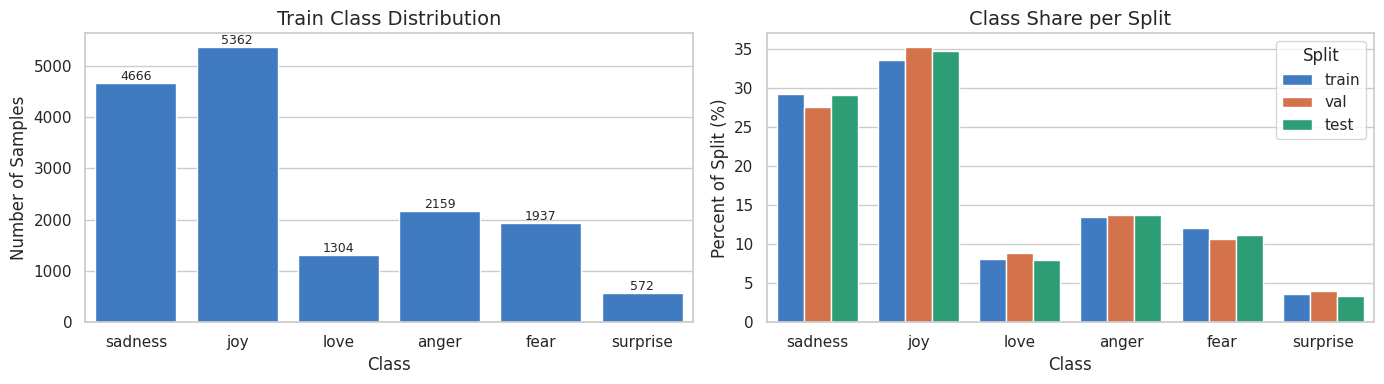

In [8]:
# ============================================================
# 3) Label distribution
# ============================================================
display(Markdown("## 3. Label Distribution"))

# Fixed colours per split, reused by later plots so a split keeps its colour
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}

dist_table = pd.DataFrame(index=label_names)
dist_table.index.name = "label_name"
pct_rows = []
for part in [train_df, val_df, test_df]:
    name = part["split"].iloc[0]
    counts = part["label_name"].value_counts()
    dist_table[name] = counts
    dist_table[name + "_%"] = (100 * counts / len(part)).round(2)
    for cls in label_names:
        pct_rows.append({"label_name": cls, "split": name, "percent": 100 * counts.get(cls, 0) / len(part)})
pct_long = pd.DataFrame(pct_rows)
display(dist_table)

# Imbalance is measured on train, the split the models learn from
label_counts = dist_table["train"]
imbalance_ratio = label_counts.max() / label_counts.min()
print(f"Largest class : {label_counts.idxmax()} ({label_counts.max()})")
print(f"Smallest class: {label_counts.idxmin()} ({label_counts.min()})")
print(f"Imbalance ratio (train): {imbalance_ratio:.2f}")

# Same formula as sklearn class_weight="balanced": n_samples / (n_classes * count).
# Preview only, on unfiltered train; the weights actually used are computed in block 12 after filtering
weights_preview = (len(train_df) / (len(label_names) * label_counts)).round(4)
display(pd.DataFrame({"train_count": label_counts, "balanced_weight": weights_preview}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(x=label_counts.index, y=label_counts.values, order=label_names, color=SPLIT_COLORS["train"], ax=axes[0])
axes[0].set_title("Train Class Distribution", fontsize=14)
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Samples")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom", fontsize=9)

# Percent instead of counts, because train is 8x larger than val and test
sns.barplot(data=pct_long, x="label_name", y="percent", hue="split", order=label_names,
            hue_order=["train", "val", "test"], palette=SPLIT_COLORS, ax=axes[1])
axes[1].set_title("Class Share per Split", fontsize=14)
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Percent of Split (%)")
axes[1].legend(title="Split")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_class_dist.png"), dpi=150)
plt.show()

## Duplicate audit
Find texts repeated inside a split, shared between splits (leakage) and repeated with different labels (label noise), on the normalised key of proposal §6. Nothing is removed yet: the filtering rules are applied in a later block.

In [9]:
# ============================================================
# 4) Duplicate audit
# ============================================================
display(Markdown("## 4. Duplicate Audit"))

def make_key(text):
    # Normalisation from proposal §6: NFC -> lowercase -> trim -> collapse whitespace
    text = unicodedata.normalize("NFC", text).lower().strip()
    return re.sub(r"\s+", " ", text)

for part in [train_df, val_df, test_df]:
    part["text_key"] = part["text"].apply(make_key)

def count_repeated(part, col):
    # Number of texts that appear 2+ times inside one split (groups, not extra rows)
    counts = part[col].value_counts()
    return int((counts >= 2).sum())

def count_shared(part_a, part_b, col):
    # Number of distinct texts found in both splits
    return len(set(part_a[col]) & set(part_b[col]))

dup_rows = []
for part in [train_df, val_df, test_df]:
    name = part["split"].iloc[0]
    dup_rows.append({
        "Scope": f"Within {name}",
        "Exact text": count_repeated(part, "text"),
        "Normalized key": count_repeated(part, "text_key"),
    })
for part_a, part_b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    name_a = part_a["split"].iloc[0]
    name_b = part_b["split"].iloc[0]
    dup_rows.append({
        "Scope": f"{name_a}-{name_b} overlap",
        "Exact text": count_shared(part_a, part_b, "text"),
        "Normalized key": count_shared(part_a, part_b, "text_key"),
    })

dup_df = pd.DataFrame(dup_rows).set_index("Scope")
display(dup_df)

## 4. Duplicate Audit

,Exact text,Normalized key
Scope,,
Within train,31,31
Within val,2,2
Within test,0,0
train-val overlap,5,5
train-test overlap,11,11
val-test overlap,3,3


In [10]:
# ============================================================
# 5) Conflicting labels
# ============================================================
display(Markdown("## 5. Same Text, Different Labels"))

# All 20,000 rows together, so a text shared by two splits counts as one group
all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

group_stats = all_df.groupby("text_key").agg(rows=("label", "size"), n_labels=("label", "nunique"))
repeated_groups = group_stats[group_stats["rows"] >= 2]
conflict_groups = repeated_groups[repeated_groups["n_labels"] >= 2]
conflict_rows = int(conflict_groups["rows"].sum())

# Test rows are never removed (rule 1), so conflicts that touch test stay as a documented limitation
test_keys = set(test_df["text_key"])
conflict_with_test = 0
for key in conflict_groups.index:
    if key in test_keys:
        conflict_with_test += 1

conflict_summary = pd.DataFrame({
    "": ["Repeated-text groups", "Groups with conflicting labels", "Rows in conflicting groups",
         "Conflicting groups that include a test row"],
    "Value": [len(repeated_groups), len(conflict_groups), conflict_rows, conflict_with_test],
}).set_index("")
display(conflict_summary)

# Every group has at least 2 rows, so a max of 2 means every conflicting group is exactly one pair
print("Max rows in one conflicting group:", conflict_groups["rows"].max())

# A few examples, to see what the conflicts look like
example_keys = conflict_groups.index[:5]
conflict_examples = all_df[all_df["text_key"].isin(example_keys)].sort_values(["text_key", "split"])
display(conflict_examples[["text", "split", "orig_idx", "label_name"]])

## 5. Same Text, Different Labels

,Value
,
Repeated-text groups,52
Groups with conflicting labels,51
Rows in conflicting groups,102
Conflicting groups that include a test row,14


Max rows in one conflicting group: 2


,text,split,orig_idx,label_name
18502,i am feeling stressed and more than a bit anxious,test,502,anger
11898,i am feeling stressed and more than a bit anxious,train,11898,sadness
3508,i am not amazing or great at photography but i feel passionate about it,train,3508,joy
8246,i am not amazing or great at photography but i feel passionate about it,train,8246,love
5277,i began to feel accepted by gaia on her own terms,train,5277,love
15705,i began to feel accepted by gaia on her own terms,train,15705,joy
8804,i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,train,8804,fear
15572,i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,train,15572,anger
11013,i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,train,11013,love
12892,i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,train,12892,joy


## Text length
Length in characters and words per split and per class. This gives a first idea of `MAX_LEN` (confirmed later with real tokens) and shows whether one class is simply longer than the others.

In [11]:
# ============================================================
# 6) Text length analysis
# ============================================================
display(Markdown("## 6. Text Length Analysis"))

# Measured on the original text. Words are whitespace-separated, not model tokens (tokens: block 11)
for part in [train_df, val_df, test_df]:
    part["char_len"] = part["text"].str.len()
    part["word_len"] = part["text"].str.split().str.len()

def length_stats(values):
    return [values.min(), values.median(), round(values.mean(), 2), round(values.quantile(0.95), 2), values.max()]

len_table = pd.DataFrame({
    "Stat": ["Min", "Median", "Mean", "P95", "Max"],
    "Chars": length_stats(train_df["char_len"]),
    "Words": length_stats(train_df["word_len"]),
}).set_index("Stat")
display(len_table)

# Val and test should not be much longer than train, otherwise MAX_LEN must cover them too
split_len_rows = []
for part in [train_df, val_df, test_df]:
    split_len_rows.append({
        "Split": part["split"].iloc[0],
        "Median words": part["word_len"].median(),
        "P95 words": round(part["word_len"].quantile(0.95), 2),
        "Max words": part["word_len"].max(),
    })
display(pd.DataFrame(split_len_rows).set_index("Split"))

len_by_class = pd.DataFrame({
    "Median words": train_df.groupby("label_name")["word_len"].median(),
    "Mean words": train_df.groupby("label_name")["word_len"].mean().round(2),
    "P95 words": train_df.groupby("label_name")["word_len"].quantile(0.95).round(2),
}).reindex(label_names)
display(len_by_class)

## 6. Text Length Analysis

,Chars,Words
Stat,,
Min,7.00,2.00
Median,86.00,17.00
Mean,96.85,19.17
P95,207.05,41.00
Max,300.00,66.00


,Median words,P95 words,Max words
Split,,,
train,17.0,41.0,66
val,17.0,40.0,61
test,17.0,41.0,61


,Median words,Mean words,P95 words
label_name,,,
sadness,16.0,18.36,41.0
joy,18.0,19.50,40.0
love,19.0,20.70,41.0
anger,17.0,19.23,41.0
fear,17.0,18.84,41.0
surprise,18.0,19.97,42.0


## 7. Text Length Plots

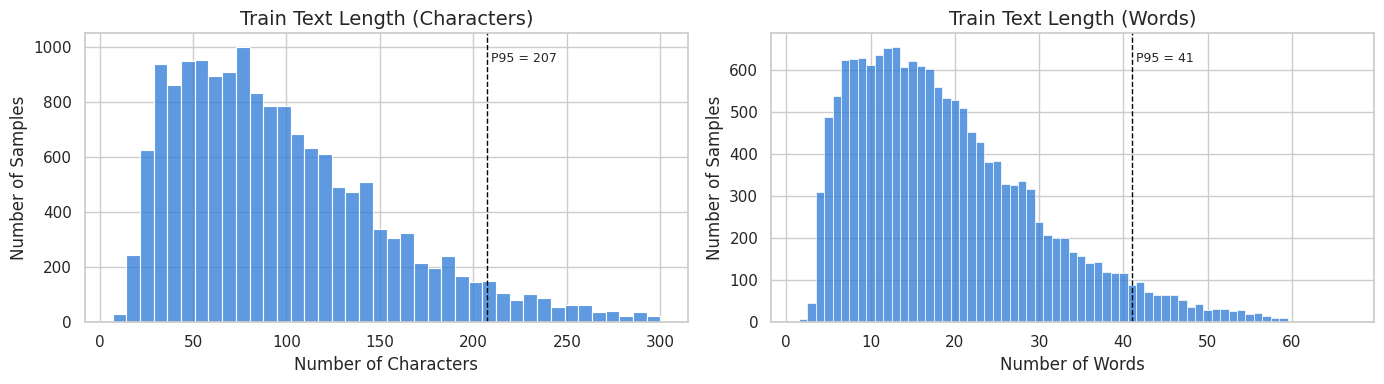

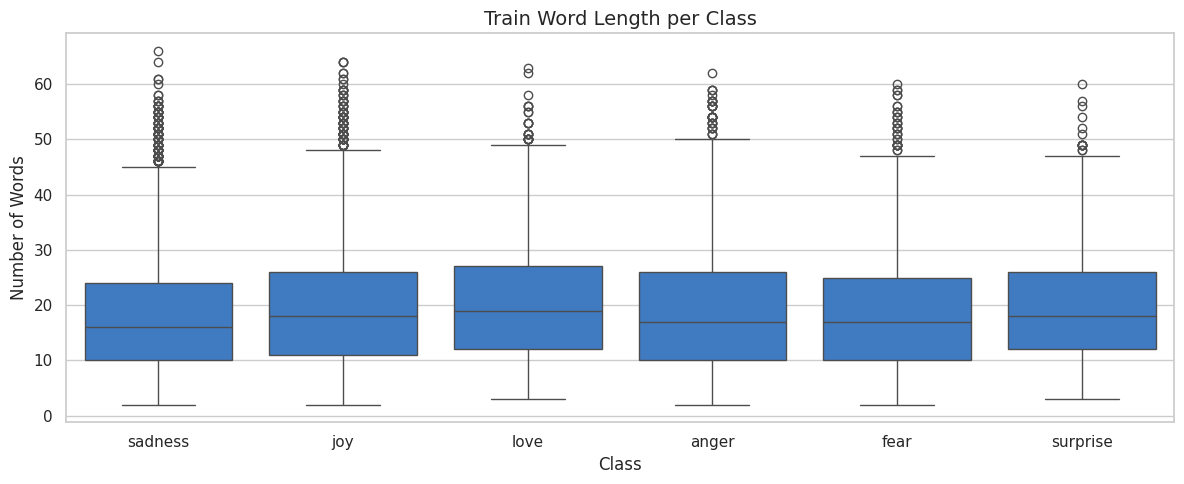

In [12]:
# ============================================================
# 7) Text length plots
# ============================================================
display(Markdown("## 7. Text Length Plots"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, unit in [(axes[0], "char_len", "Characters"), (axes[1], "word_len", "Words")]:
    if col == "word_len":
        # Word counts are whole numbers: one bar per value, otherwise bars alternate high/low
        sns.histplot(train_df[col], discrete=True, color=SPLIT_COLORS["train"], ax=ax)
    else:
        sns.histplot(train_df[col], bins=40, color=SPLIT_COLORS["train"], ax=ax)
    p95 = train_df[col].quantile(0.95)
    ax.axvline(p95, color="black", linestyle="--", linewidth=1)
    ax.text(p95, ax.get_ylim()[1] * 0.9, f" P95 = {p95:.0f}", fontsize=9)
    ax.set_title(f"Train Text Length ({unit})", fontsize=14)
    ax.set_xlabel(f"Number of {unit}")
    ax.set_ylabel("Number of Samples")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_text_len.png"), dpi=150)
plt.show()

# If one class were much longer than the others, a model could learn length instead of emotion
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=train_df, x="label_name", y="word_len", order=label_names, color=SPLIT_COLORS["train"], ax=ax)
ax.set_title("Train Word Length per Class", fontsize=14)
ax.set_xlabel("Class")
ax.set_ylabel("Number of Words")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_text_len_class.png"), dpi=150)
plt.show()

## Filtering
Apply the four rules of proposal §5 in their stated order on the normalised key: (1) test is kept as released and train/val rows whose text is in test are removed; (2) train–val overlaps keep the val copy; (3) inside train and inside val, every row of a text with conflicting labels is removed; (4) same-label duplicates keep the first row in the released order. Then check that no text is shared between splits.

In [13]:
# ============================================================
# 8) Apply the filtering rules (proposal §5)
# ============================================================
display(Markdown("## 8. Filtering Rules"))

# Run this cell once, right after the EDA cells: a second run would remove nothing and log zeros
rows_before = {"train": len(train_df), "val": len(val_df), "test": len(test_df)}
removal_log = []

def log_removal(rule, split_name, n_rows):
    removal_log.append({"Rule": rule, "Split": split_name, "Rows removed": n_rows})

def drop_within_split(part):
    name = part["split"].iloc[0]

    # Rule 3: drop every row of a text whose copies disagree on the label (no label is chosen or invented)
    n_labels = part.groupby("text_key")["label"].transform("nunique")
    conflict = n_labels > 1
    log_removal("3. Conflicting labels", name, int(conflict.sum()))
    part = part[~conflict]

    # Rule 4: same text with the same label -> keep the first row in the released order
    part = part.sort_values("orig_idx")
    duplicate = part.duplicated(subset="text_key", keep="first")
    log_removal("4. Same-label duplicate", name, int(duplicate.sum()))
    part = part[~duplicate]
    return part

if APPLY_FILTERING:
    # Rule 1: test is kept as released; drop train and val rows whose text is also in test
    test_keys = set(test_df["text_key"])
    in_test = train_df["text_key"].isin(test_keys)
    log_removal("1. Text also in test", "train", int(in_test.sum()))
    train_df = train_df[~in_test]

    in_test = val_df["text_key"].isin(test_keys)
    log_removal("1. Text also in test", "val", int(in_test.sum()))
    val_df = val_df[~in_test]

    # Rule 2: for train-val overlaps keep the val copy and drop the train copy
    in_val = train_df["text_key"].isin(set(val_df["text_key"]))
    log_removal("2. Text also in val", "train", int(in_val.sum()))
    train_df = train_df[~in_val]

    # Rules 3 and 4, inside train and inside val separately
    train_df = drop_within_split(train_df)
    val_df = drop_within_split(val_df)

    removal_df = pd.DataFrame(removal_log).sort_values(["Rule", "Split"]).reset_index(drop=True)
    display(removal_df)
else:
    print("APPLY_FILTERING = False: the official splits are kept unfiltered")

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

## 8. Filtering Rules

,Rule,Split,Rows removed
0,1. Text also in test,train,11
1,1. Text also in test,val,3
2,2. Text also in val,train,5
3,3. Conflicting labels,train,60
4,3. Conflicting labels,val,4
5,4. Same-label duplicate,train,1
6,4. Same-label duplicate,val,0


In [14]:
# ============================================================
# 9) Splits after filtering
# ============================================================
display(Markdown("## 9. Splits After Filtering"))

total_after = len(train_df) + len(val_df) + len(test_df)
size_rows = []
for part in [train_df, val_df, test_df]:
    name = part["split"].iloc[0]
    size_rows.append({
        "Split": name,
        "Before": rows_before[name],
        "Removed": rows_before[name] - len(part),
        "After": len(part),
        "Percent": round(100 * len(part) / total_after, 2),
    })
split_size_df = pd.DataFrame(size_rows).set_index("Split")
display(split_size_df)

# Class counts and shares per split after filtering (exported later as split_stats.csv)
split_stats = pd.DataFrame(index=label_names)
split_stats.index.name = "label_name"
for part in [train_df, val_df, test_df]:
    name = part["split"].iloc[0]
    counts = part["label_name"].value_counts()
    split_stats[name] = counts
    split_stats[name + "_%"] = (100 * counts / len(part)).round(2)
display(split_stats)

# Checks promised in proposal §5-§6
classes_ok = True
for part in [train_df, val_df, test_df]:
    if part["label"].nunique() != len(label_names):
        classes_ok = False

checks = {
    "train-val overlap = 0": len(set(train_df["text_key"]) & set(val_df["text_key"])) == 0,
    "train-test overlap = 0": len(set(train_df["text_key"]) & set(test_df["text_key"])) == 0,
    "val-test overlap = 0": len(set(val_df["text_key"]) & set(test_df["text_key"])) == 0,
    "no repeated text inside train": train_df["text_key"].is_unique,
    "no repeated text inside val": val_df["text_key"].is_unique,
    "train has at least 5,000 rows": len(train_df) >= 5000,
    "all 6 classes in every split": classes_ok,
}
for check, ok in checks.items():
    print("OK  " if ok else "FAIL", check)

if APPLY_FILTERING:
    assert all(checks.values()), "A filtering check failed, see the list above"

## 9. Splits After Filtering

,Before,Removed,After,Percent
Split,,,,
train,16000,77,15923,79.95
val,2000,7,1993,10.01
test,2000,0,2000,10.04


,train,train_%,val,val_%,test,test_%
label_name,,,,,,
sadness,4661,29.27,550,27.60,581,29.05
joy,5340,33.54,702,35.22,695,34.75
love,1283,8.06,176,8.83,159,7.95
anger,2152,13.52,274,13.75,275,13.75
fear,1923,12.08,211,10.59,224,11.20
surprise,564,3.54,80,4.01,66,3.30


OK   train-val overlap = 0
OK   train-test overlap = 0
OK   val-test overlap = 0
OK   no repeated text inside train
OK   no repeated text inside val
OK   train has at least 5,000 rows
OK   all 6 classes in every split


## Preprocessing
Two text versions. `text_min` (NFC, lowercase, trim, collapse whitespace) is used by DistilBERT and by the main baseline; DistilBERT's own WordPiece tokenizer does the rest. `text_aggr` also removes non-alphanumerics and sklearn's English stopwords, except a keep-list of negations, intensifiers and "but"; it is only used for the baseline's extra experiment (stopwords removed vs kept).

In [15]:
# ============================================================
# 10) Preprocessing variants
# ============================================================
display(Markdown("## 10. Preprocessing Variants"))

# sklearn's list (318 words) contains negations and intensifiers, which carry emotion:
# "not happy" must not become "happy". These words are kept even in the aggressive version.
KEEP_WORDS = {
    "not", "no", "nor", "never", "none", "nothing", "nobody", "nowhere", "neither",
    "cannot", "cant", "couldnt", "without",
    "very", "so", "too", "more", "most", "much", "less", "least", "enough",
    "but",
}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - KEEP_WORDS

def clean_min(text):
    # Minimal: the same normalisation as the duplicate key (NFC, lowercase, trim, collapse whitespace)
    return make_key(text)

def clean_aggr(text):
    text = make_key(text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)  # keep only letters, digits and spaces
    tokens = [w for w in text.split() if w not in STOP_WORDS]
    return " ".join(tokens)

for part in [train_df, val_df, test_df]:
    part["text_min"] = part["text"].apply(clean_min)
    part["text_aggr"] = part["text"].apply(clean_aggr)

print("Stopwords removed in text_aggr:", len(STOP_WORDS), "| kept from sklearn's list:", len(KEEP_WORDS & ENGLISH_STOP_WORDS))

# Corpus statistics on train (whitespace tokens)
stats_rows = []
for col in ["text", "text_min", "text_aggr"]:
    n_tokens = train_df[col].str.split().str.len()
    vocab = set()
    for t in train_df[col]:
        vocab.update(t.split())
    stats_rows.append({
        "Version": col,
        "Vocabulary size": len(vocab),
        "Mean tokens per text": round(n_tokens.mean(), 2),
        "Total tokens": int(n_tokens.sum()),
        "Empty texts": int((n_tokens == 0).sum()),
    })
display(pd.DataFrame(stats_rows).set_index("Version"))

# Before / after on texts with a negation, to check the keep-list works
has_negation = train_df["text_min"].str.contains(r"\b(?:not|never|no)\b")
display(train_df.loc[has_negation, ["text", "text_min", "text_aggr", "label_name"]].head(5))

## 10. Preprocessing Variants

Stopwords removed in text_aggr: 295 | kept from sklearn's list: 23


,Vocabulary size,Mean tokens per text,Total tokens,Empty texts
Version,,,,
text,15188,19.18,305403,0
text_min,15188,19.18,305403,0
text_aggr,14917,9.31,148202,0


,text,text_min,text_aggr,label_name
14,i have immense sympathy with the general point but as a possible proto writer trying to find time to write in the co...,i have immense sympathy with the general point but as a possible proto writer trying to find time to write in the co...,immense sympathy general point but possible proto writer trying time write corners life no sign agent let publishing...,joy
15,i do not feel reassured anxiety is on each side,i do not feel reassured anxiety is on each side,not feel reassured anxiety,joy
25,i still love my so and wish the best for him i can no longer tolerate the effect that bm has on our lives and the fa...,i still love my so and wish the best for him i can no longer tolerate the effect that bm has on our lives and the fa...,love so wish best no longer tolerate effect bm lives fact turned so bitter angry person not particularly kind people...,sadness
33,i climbed the hill feeling frustrated that id pretty much paced entirely wrong for this course and that a factor tha...,i climbed the hill feeling frustrated that id pretty much paced entirely wrong for this course and that a factor tha...,climbed hill feeling frustrated id pretty much paced entirely wrong course factor never hampered dent day,anger
35,i am not sure what would make me feel content if anything,i am not sure what would make me feel content if anything,not sure make feel content,joy


## Vocabulary and n-grams
Vocabulary size, rare words and out-of-vocabulary rate of val/test against the train vocabulary, then the n-grams that are most frequent and most specific for each class. Everything is computed on train only.

In [16]:
# ============================================================
# 11) Vocabulary analysis (train only)
# ============================================================
display(Markdown("## 11. Vocabulary Analysis (Train)"))

# Vocabulary is built from train only; val and test are only checked against it
train_counter = Counter()
doc_counter = Counter()          # in how many train texts each word appears
for t in train_df["text_min"]:
    words = t.split()
    train_counter.update(words)
    doc_counter.update(set(words))
train_vocab = set(train_counter)

def oov_rate(part):
    # Percent of tokens in a split that never appear in train
    n_tokens = 0
    n_oov = 0
    for t in part["text_min"]:
        for w in t.split():
            n_tokens += 1
            if w not in train_vocab:
                n_oov += 1
    return round(100 * n_oov / n_tokens, 2)

seen_once = 0
for c in train_counter.values():
    if c == 1:
        seen_once += 1

vocab_summary = pd.DataFrame({
    "": ["Train vocabulary size", "Words seen only once", "Words seen only once (%)",
         "OOV rate val (%)", "OOV rate test (%)"],
    "Value": [len(train_vocab), seen_once, round(100 * seen_once / len(train_vocab), 2),
              oov_rate(val_df), oov_rate(test_df)],
}).set_index("")
display(vocab_summary)

# How many of the most frequent words cover most of the text
freqs = np.array(sorted(train_counter.values(), reverse=True))
cum_coverage = np.cumsum(freqs) / freqs.sum()
coverage_rows = []
for k in [100, 500, 1000, 2000, 5000, 10000]:
    k = min(k, len(freqs))
    coverage_rows.append({"Top-k words": k, "Token coverage (%)": round(100 * cum_coverage[k - 1], 2)})
display(pd.DataFrame(coverage_rows).set_index("Top-k words"))

# Most common words, with the share of train texts that contain them
top_words = pd.DataFrame(train_counter.most_common(15), columns=["word", "count"])
top_words["texts containing it (%)"] = (100 * top_words["word"].map(doc_counter) / len(train_df)).round(1)
display(top_words.set_index("word"))

## 11. Vocabulary Analysis (Train)

,Value
,
Train vocabulary size,15188.00
Words seen only once,7816.00
Words seen only once (%),51.46
OOV rate val (%),2.72
OOV rate test (%),2.74


,Token coverage (%)
Top-k words,
100,59.62
500,77.69
1000,85.12
2000,90.82
5000,95.81
10000,98.30


,count,texts containing it (%)
word,,
i,25745,93.2
feel,11120,66.4
and,9548,44.0
to,8944,39.7
the,8333,36.3
a,6173,30.9
feeling,5101,31.1
that,5093,25.6
of,4961,25.3


## 12. Top N-grams per Class (Train)

**Most frequent n-grams per class**

class,sadness,joy,love,anger,fear,surprise
rank,,,,,,
1,feel,feel,feel,feel,feel,feel
2,feeling,feeling,feeling,feeling,feeling,feeling
3,like,like,like,like,im,like
4,so,im,im,im,but,but
5,im,so,so,so,so,so
6,but,but,feel like,but,like,im
7,not,not,but,not,not,amazed
8,feel like,feel like,not,feel like,just,not
9,just,more,more,just,little,impressed


**Most class-specific n-grams per class** (share of all occurrences in this class)

class,sadness,joy,love,anger,fear,surprise
rank,,,,,,
1,feel unwelcome (100.0%),invigorated (100.0%),sympathetic (100.0%),feel offended (100.0%),distressed (100.0%),feel amazed (100.0%)
2,neglectful (100.0%),feel special (100.0%),feel longing (100.0%),feel cold (100.0%),feel intimidated (100.0%),dazed (97.0%)
3,like missed (100.0%),clever (100.0%),feel sympathetic (100.0%),feel resentful (100.0%),feel threatened (100.0%),impressed (96.8%)
4,inadequate (100.0%),terrific (100.0%),fond (100.0%),feel wronged (100.0%),apprehensive (100.0%),stunned (95.0%)
5,feel rejected (100.0%),keen (100.0%),compassionate (100.0%),feeling cranky (100.0%),suspicious (100.0%),amazed (94.4%)
6,feel unimportant (100.0%),sociable (100.0%),horny (100.0%),envious (100.0%),feel pressured (100.0%),curious (93.1%)
7,deprived (100.0%),feel invigorated (100.0%),loyal (97.8%),feel frustrated (100.0%),feel reluctant (100.0%),shocked (88.2%)
8,disillusioned (100.0%),lively (100.0%),tender (95.6%),feel insulted (100.0%),distraught (100.0%),surprised (84.6%)
9,disheartened (100.0%),smug (100.0%),longing (94.4%),heartless (100.0%),feel afraid (100.0%),funny (71.0%)


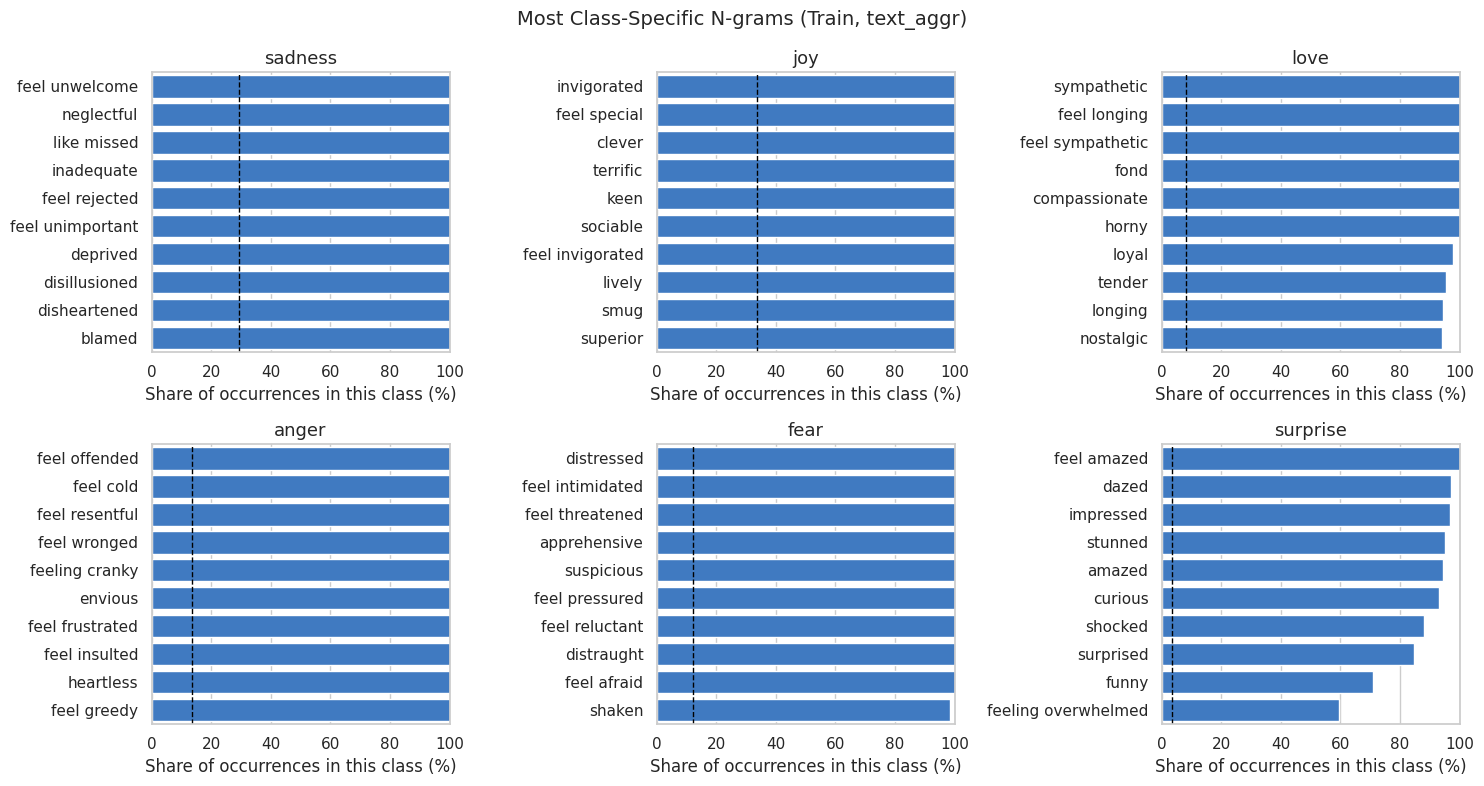

In [17]:
# ============================================================
# 12) Top n-grams per class (train only)
# ============================================================
display(Markdown("## 12. Top N-grams per Class (Train)"))

TOP_K = 10
MIN_NGRAM_COUNT = 20    # rarer n-grams are skipped in the "class-specific" ranking, their share is too noisy

# Uni- and bigram counts on text_aggr, so "i", "the", "and" do not fill every list
count_vec = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_counts = count_vec.fit_transform(train_df["text_aggr"])
ngrams = np.array(count_vec.get_feature_names_out())
total_counts = np.asarray(X_counts.sum(axis=0)).ravel()

frequent_rows = []
specific_rows = []
for cls in label_names:
    in_class = (train_df["label_name"] == cls).to_numpy()
    counts = np.asarray(X_counts[in_class].sum(axis=0)).ravel()

    # Most frequent n-grams of the class
    for rank, idx in enumerate(counts.argsort()[::-1][:TOP_K], start=1):
        frequent_rows.append({"rank": rank, "class": cls, "ngram": ngrams[idx]})

    # Most class-specific: share of all occurrences of the n-gram that fall in this class
    share = np.where(total_counts >= MIN_NGRAM_COUNT, counts / total_counts, 0)
    for rank, idx in enumerate(share.argsort()[::-1][:TOP_K], start=1):
        specific_rows.append({"rank": rank, "class": cls, "ngram": ngrams[idx],
                              "count": int(counts[idx]), "share_%": round(100 * share[idx], 1)})

frequent_df = pd.DataFrame(frequent_rows)
specific_df = pd.DataFrame(specific_rows)

display(Markdown("**Most frequent n-grams per class**"))
display(frequent_df.pivot(index="rank", columns="class", values="ngram")[label_names])
display(Markdown("**Most class-specific n-grams per class** (share of all occurrences in this class)"))
specific_df["shown"] = specific_df["ngram"] + " (" + specific_df["share_%"].astype(str) + "%)"
display(specific_df.pivot(index="rank", columns="class", values="shown")[label_names])

# One panel per class; the dashed line is the class's share of train rows,
# so a bar far to the right of it marks an n-gram that points strongly to that class
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, cls in zip(axes.ravel(), label_names):
    sub = specific_df[specific_df["class"] == cls]
    sns.barplot(data=sub, x="share_%", y="ngram", color=SPLIT_COLORS["train"], ax=ax)
    ax.axvline(100 * (train_df["label_name"] == cls).mean(), color="black", linestyle="--", linewidth=1)
    ax.set_title(cls, fontsize=13)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Share of occurrences in this class (%)")
    ax.set_ylabel("")
plt.suptitle("Most Class-Specific N-grams (Train, text_aggr)", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_top_ngrams.png"), dpi=150)
plt.show()

## DistilBERT tokenizer
Token lengths with DistilBERT's own WordPiece tokenizer (including `[CLS]` and `[SEP]`) on `text_min`, to confirm `MAX_LEN` = 128 from the proposal: how many texts would be truncated, and how much shorter a limit could be.

In [18]:
# ============================================================
# 13) DistilBERT token lengths
# ============================================================
display(Markdown("## 13. DistilBERT Token Lengths"))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"Tokenizer: {type(tokenizer).__name__} | WordPiece vocabulary: {tokenizer.vocab_size} tokens")

# Count tokens with [CLS] and [SEP] and without truncation, so texts longer than MAX_LEN show up
for part in [train_df, val_df, test_df]:
    encoded = tokenizer(part["text_min"].tolist(), add_special_tokens=True, truncation=False)
    part["token_len"] = [len(ids) for ids in encoded["input_ids"]]

token_rows = []
for part in [train_df, val_df, test_df]:
    lens = part["token_len"]
    token_rows.append({
        "Split": part["split"].iloc[0],
        "Median": lens.median(),
        "Mean": round(lens.mean(), 2),
        "P95": lens.quantile(0.95),
        "P99": lens.quantile(0.99),
        "Max": lens.max(),
        f"Texts > {MAX_LEN}": int((lens > MAX_LEN).sum()),
        "Truncated (%)": round(100 * (lens > MAX_LEN).mean(), 2),
    })
display(pd.DataFrame(token_rows).set_index("Split"))

# WordPiece splits rare words into pieces, so a text has more tokens than words
tokens_per_word = (train_df["token_len"] - 2).sum() / train_df["word_len"].sum()
print(f"WordPiece tokens per word (train): {tokens_per_word:.2f}")

# Share of train texts that fit without truncation for a few candidate lengths
for max_len in [64, 96, 128]:
    fits = 100 * (train_df["token_len"] <= max_len).mean()
    print(f"max_length = {max_len:3d}: {fits:6.2f}% of train texts fit")

# One example where a word is split into "##" pieces
for t in train_df["text_min"]:
    pieces = tokenizer.tokenize(t)
    if any(p.startswith("##") for p in pieces):
        print("\nText  :", t)
        print("Tokens:", pieces)
        break

## 13. DistilBERT Token Lengths

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer: BertTokenizer | WordPiece vocabulary: 30522 tokens


,Median,Mean,P95,P99,Max,Texts > 128,Truncated (%)
Split,,,,,,,
train,20.0,22.27,45.0,57.0,87,0,0.0
val,20.0,21.89,44.0,56.0,69,0,0.0
test,20.0,22.21,45.0,55.0,66,0,0.0


WordPiece tokens per word (train): 1.06
max_length =  64:  99.84% of train texts fit
max_length =  96: 100.00% of train texts fit
max_length = 128: 100.00% of train texts fit

Text  : i didnt feel humiliated
Tokens: ['i', 'didn', '##t', 'feel', 'humiliated']


# Training Setup

## Label mapping
One label mapping shared by both models, and the integer labels of the filtered train and val splits. Class weights are not computed here: the baseline uses sklearn's `class_weight="balanced"`, and DistilBERT computes the same weights from `y_train` inside its training function, only when `USE_CLASS_WEIGHTS` is on.

In [19]:
# ============================================================
# 14) Label mapping
# ============================================================
display(Markdown("## 14. Label Mapping"))

# id2label comes from the dataset when loading; label2id is its reverse, used by the DistilBERT config
label2id = {name: i for i, name in id2label.items()}
num_classes = len(label_names)
print("id2label   :", id2label)
print("label2id   :", label2id)
print("num_classes:", num_classes)

# Integer labels of the filtered splits; test labels are only used in the final evaluation
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
print("y_train:", y_train.shape, "| y_val:", y_val.shape)

## 14. Label Mapping

id2label   : {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}
label2id   : {'sadness': 0, 'joy': 1, 'love': 2, 'anger': 3, 'fear': 4, 'surprise': 5}
num_classes: 6
y_train: (15923,) | y_val: (1993,)


## Helper functions
Functions shared by the baseline and DistilBERT, so both are measured the same way: metrics (Accuracy, Macro-F1, Weighted-F1), a per-class table, a confusion matrix, parameter count, model size on disk, a GPU-safe timer and the wandb run starter. The last lines check the metric helper on a model that always predicts the largest class: the floor any real model must beat on val.

In [20]:
# ============================================================
# 15) Helper functions
# ============================================================
display(Markdown("## 15. Helper Functions"))

def compute_metrics(y_true, y_pred):
    # Macro-F1 selects the model (every class counts equally); accuracy and weighted-F1 are for reference
    return {
        "acc": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    }

def per_class_table(y_true, y_pred):
    # Precision / recall / F1 / support per class, saved later as per_class_<run>.csv
    report = classification_report(y_true, y_pred, labels=np.arange(num_classes), target_names=label_names,
                                   output_dict=True, zero_division=0)
    return pd.DataFrame(report).T.round(4)

def plot_confusion_matrix(y_true, y_pred, title, save_name=None):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
    # Colour = share of each true class (row sums to 1, the diagonal is the recall); numbers = counts
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=label_names, yticklabels=label_names, ax=ax)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    plt.tight_layout()
    if save_name is not None:
        plt.savefig(os.path.join(FIG_DIR, save_name), dpi=150)
    plt.show()

def count_params(model):
    # PyTorch model: all parameters, and the ones the optimizer updates (fewer when the backbone is frozen)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def size_mb(path):
    # Size on disk of a saved model: one file (joblib) or a folder (Hugging Face checkpoint)
    if os.path.isfile(path):
        return round(os.path.getsize(path) / 1024**2, 2)
    total = 0
    for root, _, files in os.walk(path):
        for name in files:
            total += os.path.getsize(os.path.join(root, name))
    return round(total / 1024**2, 2)

def sync_time():
    # GPU work runs asynchronously: wait for it to finish before reading the clock
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

def start_wandb_run(run_name, config):
    # One wandb run per model run; its id is saved so the final test block can reopen the same run
    run = wandb.init(project=WANDB_PROJECT, name=run_name, config=config)
    ids = {}
    if os.path.exists(WANDB_IDS_PATH):
        with open(WANDB_IDS_PATH) as f:
            ids = json.load(f)
    ids[run_name] = run.id
    with open(WANDB_IDS_PATH, "w") as f:
        json.dump(ids, f, indent=2)
    return run

# One dict per run and split; becomes results_df and results.csv for the site
results = []

# Check the metric helper on a trivial model that always predicts the largest train class.
# Accuracy looks fair, Macro-F1 does not: this is the floor any real model must clear on val.
majority = np.bincount(y_train).argmax()
majority_metrics = compute_metrics(y_val, np.full_like(y_val, majority))
print(f"Always predict '{id2label[majority]}' on val ->",
      ", ".join(f"{k} = {v:.4f}" for k, v in majority_metrics.items()))

## 15. Helper Functions

Always predict 'joy' on val -> acc = 0.3522, macro_f1 = 0.0868, weighted_f1 = 0.1835


# Baseline

## TF-IDF + Logistic Regression
TF-IDF on unigrams and bigrams of `text_min`, then multinomial Logistic Regression, all fit on train only and saved to Drive with `joblib`. The baseline is run twice, with `class_weight=None` and `class_weight="balanced"`, and compared on **val only** (Macro-F1, plus F1 of the two smallest classes, surprise and love). The setting with the higher val Macro-F1 sets `USE_CLASS_WEIGHTS` for every later run, DistilBERT included. Test is not touched here.

In [21]:
# ============================================================
# 16) Baseline: TF-IDF + Logistic Regression
# ============================================================
display(Markdown("## 16. Baseline: TF-IDF + Logistic Regression"))

def run_tfidf_lr(run_name, text_col, use_class_weights):
    ckpt_path = os.path.join(CKPT_DIR, f"{run_name}.joblib")
    config = {
        "model": "tfidf_lr", "text": text_col, "ngram_range": NGRAM_RANGE, "min_df": MIN_DF, "max_df": MAX_DF,
        "C": LOGREG_C, "class_weight": "balanced" if use_class_weights else None, "seed": SEED,
    }

    # Reuse the saved model if there is one. After changing a setting in the config cell,
    # set LOAD_CKPT = False (or delete the file), otherwise the old model is loaded.
    loaded = LOAD_CKPT and os.path.exists(ckpt_path)
    if loaded:
        saved = joblib.load(ckpt_path)
        vectorizer, clf, train_time = saved["vectorizer"], saved["model"], saved["train_time_s"]
        print(f"[{run_name}] loaded from {ckpt_path}")
    else:
        # Vocabulary, IDF and classifier are all learned from train only
        vectorizer = TfidfVectorizer(ngram_range=NGRAM_RANGE, min_df=MIN_DF, max_df=MAX_DF)
        clf = LogisticRegression(C=LOGREG_C, max_iter=1000, random_state=SEED,
                                 class_weight="balanced" if use_class_weights else None)
        start = time.perf_counter()
        X_train = vectorizer.fit_transform(train_df[text_col])
        clf.fit(X_train, y_train)
        train_time = time.perf_counter() - start
        joblib.dump({"vectorizer": vectorizer, "model": clf, "train_time_s": train_time}, ckpt_path)
        print(f"[{run_name}] trained in {train_time:.1f} s, saved to {ckpt_path}")

    # Inference time includes the TF-IDF transform: a new text has to be vectorised first
    start = time.perf_counter()
    val_pred = clf.predict(vectorizer.transform(val_df[text_col]))
    infer_ms = 1000 * (time.perf_counter() - start) / len(val_df)

    metrics = compute_metrics(y_val, val_pred)
    n_params = clf.coef_.size + clf.intercept_.size   # one weight per (class, n-gram) + one bias per class

    # One row per run and split, also when this cell is run again
    results[:] = [r for r in results if not (r["run"] == run_name and r["split"] == "val")]
    results.append({
        "run": run_name, "model": "TF-IDF + LR", "text": text_col,
        "setup": "class weights on" if use_class_weights else "class weights off", "split": "val",
        **metrics, "train_time_s": round(train_time, 2), "infer_ms": round(infer_ms, 4),
        "total_params": n_params, "trainable_params": n_params, "size_mb": size_mb(ckpt_path),
        "hardware": "CPU: " + hardware_info["cpu"],
    })

    # A loaded model already has its wandb run from when it was trained
    if USE_WANDB and not loaded:
        run = start_wandb_run(run_name, config)
        wandb.log({"val_acc": metrics["acc"], "val_macro_f1": metrics["macro_f1"],
                   "val_weighted_f1": metrics["weighted_f1"], "train_time_s": train_time, "infer_ms": infer_ms})
        run.finish()

    return {"vectorizer": vectorizer, "model": clf, "val_pred": val_pred, "metrics": metrics,
            "use_class_weights": use_class_weights}

## 16. Baseline: TF-IDF + Logistic Regression

In [22]:
# ============================================================
# 17) Class weights on vs off (baseline, val only)
# ============================================================
display(Markdown("## 17. Class Weights On vs Off (Baseline, Val)"))

# Same data, features and C; the only change is class_weight=None vs "balanced"
baseline_runs = {}
for use_cw in [False, True]:
    name = "tfidf_lr_min_cw" if use_cw else "tfidf_lr_min_nocw"
    baseline_runs[name] = run_tfidf_lr(name, "text_min", use_cw)

compare_rows = []
for name, out in baseline_runs.items():
    pc = per_class_table(y_val, out["val_pred"])
    compare_rows.append({
        "run": name,
        "Accuracy": out["metrics"]["acc"],
        "Macro-F1": out["metrics"]["macro_f1"],
        "Weighted-F1": out["metrics"]["weighted_f1"],
        "F1 surprise": pc.loc["surprise", "f1-score"],
        "F1 love": pc.loc["love", "f1-score"],
        "Precision surprise": pc.loc["surprise", "precision"],
        "Recall surprise": pc.loc["surprise", "recall"],
    })
compare_df = pd.DataFrame(compare_rows).set_index("run").round(4)
display(compare_df)

# Rule agreed before the runs: the higher val Macro-F1 wins (a tie keeps the simpler run without weights),
# and the winning setting is used by every later run, DistilBERT included
best_baseline = compare_df["Macro-F1"].idxmax()
USE_CLASS_WEIGHTS = baseline_runs[best_baseline]["use_class_weights"]
gap = compare_df.loc["tfidf_lr_min_cw", "Macro-F1"] - compare_df.loc["tfidf_lr_min_nocw", "Macro-F1"]
print(f"Macro-F1 (weights on) - Macro-F1 (weights off) = {gap:+.4f}")
print(f"Selected: {best_baseline} -> USE_CLASS_WEIGHTS = {USE_CLASS_WEIGHTS}")

## 17. Class Weights On vs Off (Baseline, Val)

[tfidf_lr_min_nocw] loaded from /content/drive/MyDrive/DL/A2/checkpoints/tfidf_lr_min_nocw.joblib
[tfidf_lr_min_cw] loaded from /content/drive/MyDrive/DL/A2/checkpoints/tfidf_lr_min_cw.joblib


,Accuracy,Macro-F1,Weighted-F1,F1 surprise,F1 love,Precision surprise,Recall surprise
run,,,,,,,
tfidf_lr_min_nocw,0.8289,0.7527,0.8187,0.5517,0.6471,0.8889,0.4000
tfidf_lr_min_cw,0.8751,0.8489,0.8760,0.7692,0.8354,0.7303,0.8125


Macro-F1 (weights on) - Macro-F1 (weights off) = +0.0962
Selected: tfidf_lr_min_cw -> USE_CLASS_WEIGHTS = True


## 18. Selected Baseline (tfidf_lr_min_cw, Val)

,precision,recall,f1-score,support
sadness,0.9163,0.8764,0.8959,550.0000
joy,0.9198,0.8818,0.9004,702.0000
love,0.7534,0.9375,0.8354,176.0000
anger,0.8768,0.8832,0.8800,274.0000
fear,0.8143,0.8104,0.8124,211.0000
surprise,0.7303,0.8125,0.7692,80.0000
accuracy,0.8751,0.8751,0.8751,0.8751
macro avg,0.8352,0.8670,0.8489,1993.0000
weighted avg,0.8795,0.8751,0.8760,1993.0000


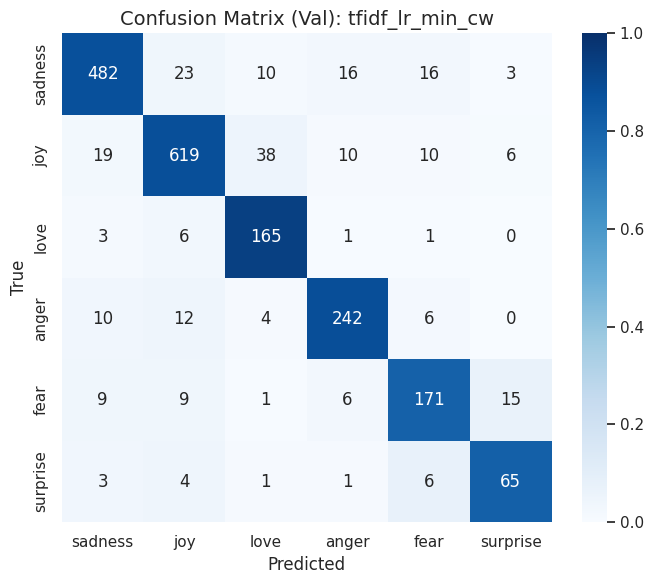

TF-IDF features (uni + bigrams, fit on train): 32776


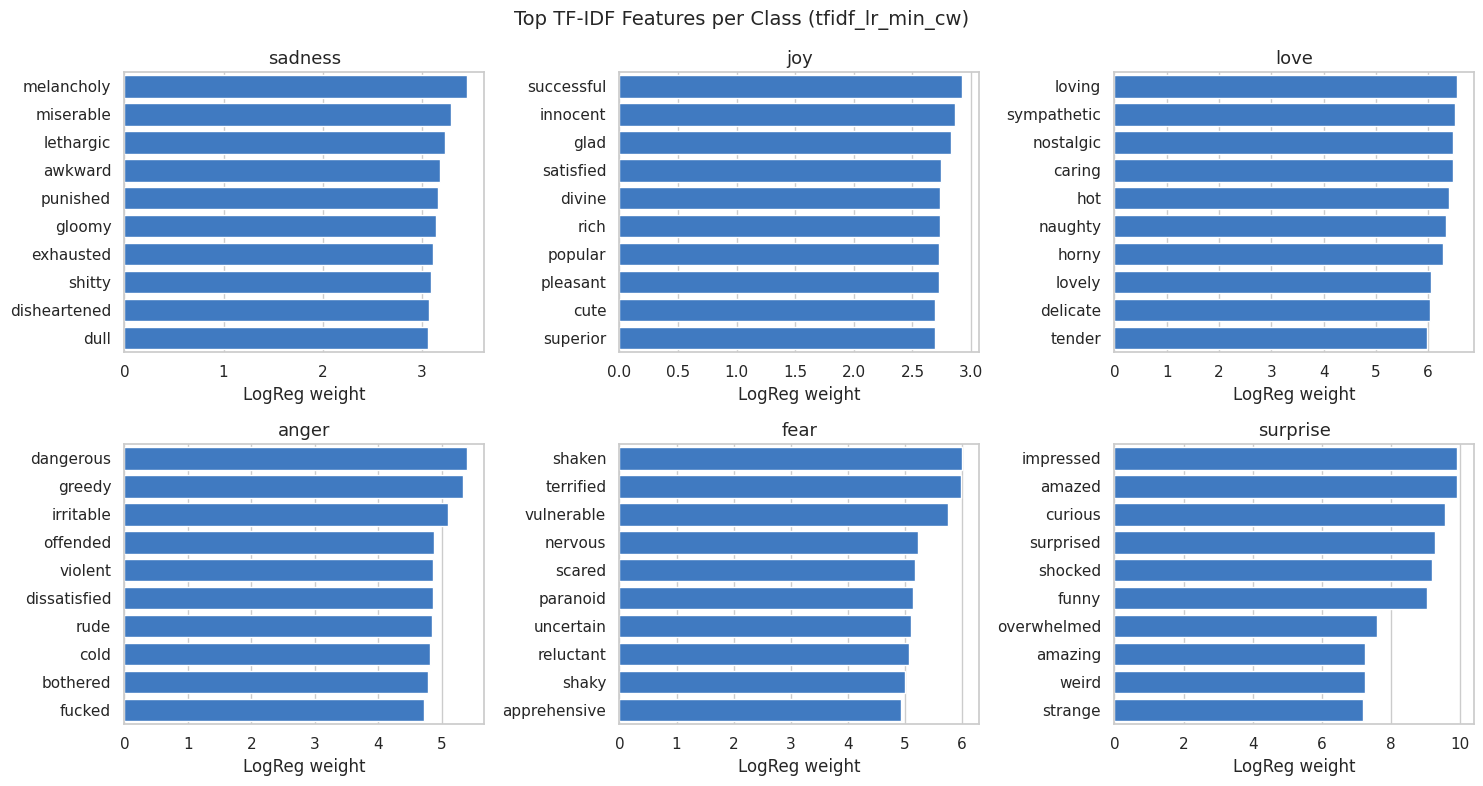

In [23]:
# ============================================================
# 18) Selected baseline: per-class results and top features
# ============================================================
display(Markdown(f"## 18. Selected Baseline ({best_baseline}, Val)"))

best_out = baseline_runs[best_baseline]
display(per_class_table(y_val, best_out["val_pred"]))
plot_confusion_matrix(y_val, best_out["val_pred"], f"Confusion Matrix (Val): {best_baseline}",
                      save_name=f"a2_cm_val_{best_baseline}.png")

# The largest LogReg weights of a class are the n-grams that push a text towards that class
feature_names = best_out["vectorizer"].get_feature_names_out()
coefs = best_out["model"].coef_
print("TF-IDF features (uni + bigrams, fit on train):", len(feature_names))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, cls_id in zip(axes.ravel(), range(num_classes)):
    top = np.argsort(coefs[cls_id])[::-1][:TOP_K]
    sns.barplot(x=coefs[cls_id][top], y=feature_names[top], color=SPLIT_COLORS["train"], ax=ax)
    ax.set_title(id2label[cls_id], fontsize=13)
    ax.set_xlabel("LogReg weight")
    ax.set_ylabel("")
plt.suptitle(f"Top TF-IDF Features per Class ({best_baseline})", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_top_features_tfidf.png"), dpi=150)
plt.show()

# DistilBERT

## Dataset and DataLoader
`TextDataset` tokenizes `text_min` once with the DistilBERT tokenizer (cut at `MAX_LEN` = 128, which no text reaches). Padding is done per batch by `DataCollatorWithPadding`, so a batch is only as long as its longest text instead of 128 tokens. Train is shuffled with a seeded generator; val keeps its order so predictions line up with `y_val`. The example batch is taken from val, so the train shuffle order is not used up before training.

In [24]:
# ============================================================
# 19) DistilBERT Dataset and DataLoader
# ============================================================
display(Markdown("## 19. DistilBERT Dataset and DataLoader"))

class TextDataset(Dataset):
    # Tokenizes every text once, cut at MAX_LEN; padding is added later, batch by batch
    def __init__(self, texts, labels, tokenizer, max_len):
        self.encodings = tokenizer(list(texts), truncation=True, max_length=max_len)
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": int(self.labels[idx]),
        }

# Pads every batch only up to its longest text, not to MAX_LEN (median text is 20 tokens)
collator = DataCollatorWithPadding(tokenizer)

def make_loader(part, shuffle):
    dataset = TextDataset(part["text_min"], part["label"].to_numpy(), tokenizer, MAX_LEN)
    # A seeded generator gives the same shuffle order on every run
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collator, generator=generator)

train_loader = make_loader(train_df, shuffle=True)
val_loader = make_loader(val_df, shuffle=False)
print(f"train: {len(train_loader.dataset)} texts -> {len(train_loader)} batches of {BATCH_SIZE} (shuffled)")
print(f"val  : {len(val_loader.dataset)} texts -> {len(val_loader)} batches of {BATCH_SIZE} (fixed order)")
print(f"Optimizer steps for {EPOCHS} epochs: {len(train_loader) * EPOCHS}")

# Example batch from val, so the train shuffle order is not used up here
batch = next(iter(val_loader))
print("\nExample batch (val):")
for key, value in batch.items():
    print(f"  {key:15s} shape {tuple(value.shape)}  {value.dtype}")
print("  labels match y_val:", torch.equal(batch["labels"], torch.tensor(y_val[:len(batch["labels"])])))
pad_share = 100 * (1 - batch["attention_mask"].float().mean().item())
print(f"  padded length {batch['input_ids'].shape[1]} tokens, {pad_share:.1f}% of the batch is [PAD]")

# First text of the batch: original, the WordPiece tokens the model sees, and its label
ids = batch["input_ids"][0]
print("\nText   :", val_df["text_min"].iloc[0])
print("Tokens :", tokenizer.convert_ids_to_tokens(ids))
print("Label  :", batch["labels"][0].item(), "=", id2label[batch["labels"][0].item()])

# Tokens fed to the model for the whole val split: per-batch padding vs padding everything to MAX_LEN
dynamic_tokens = sum(b["input_ids"].numel() for b in val_loader)
fixed_tokens = len(val_loader.dataset) * MAX_LEN
print(f"\nVal tokens with per-batch padding: {dynamic_tokens:,} | padded to {MAX_LEN}: {fixed_tokens:,} "
      f"({100 * dynamic_tokens / fixed_tokens:.1f}%)")

## 19. DistilBERT Dataset and DataLoader

train: 15923 texts -> 996 batches of 16 (shuffled)
val  : 1993 texts -> 125 batches of 16 (fixed order)
Optimizer steps for 3 epochs: 2988

Example batch (val):
  input_ids       shape (16, 34)  torch.int64
  attention_mask  shape (16, 34)  torch.int64
  labels          shape (16,)  torch.int64
  labels match y_val: True
  padded length 34 tokens, 52.8% of the batch is [PAD]

Text   : im feeling quite sad and sorry for myself but ill snap out of it soon
Tokens : ['[CLS]', 'im', 'feeling', 'quite', 'sad', 'and', 'sorry', 'for', 'myself', 'but', 'ill', 'snap', 'out', 'of', 'it', 'soon', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
Label  : 0 = sadness

Val tokens with per-batch padding: 92,045 | padded to 128: 255,104 (36.1%)


## Training function
`train_eval_transformer(run_name, freeze_backbone)` trains one DistilBERT run with the settings from the config cell and is reused by every transformer run: DistilBERT full fine-tune and frozen backbone (main controlled experiment: only `freeze_backbone` changes), the repeated seeds (`seed`) and BERT (second controlled experiment: only `model_name` changes). The encoder is `model.base_model` and the head is every parameter outside it, so the same code works for both models.

- **Same start:** seed and train shuffle order are reset at the start of every run.
- **Loss:** CrossEntropy with balanced class weights from `y_train` (the baseline comparison chose weights on).
- **Optimizer:** AdamW with two learning rates, `LR_BACKBONE` for the pretrained encoder and `LR_HEAD` for the new head, linear warmup over the first 10% of steps then linear decay, gradient clipping at `MAX_GRAD_NORM`.
- **Checkpoint:** after each epoch the model is evaluated on val; the epoch with the best val Macro-F1 is saved to Drive and reloaded at the end. Test is not used.
- **Records:** per-epoch history (`history_<run>.csv`), train time (training steps only), inference ms per text on val (tokenization included, like the baseline's TF-IDF transform), parameter counts, model size, one `results` row and the wandb run.

The quick check runs one forward pass of an untrained model on the example batch before any long training.

In [25]:
# ============================================================
# 20) Transformer training function (DistilBERT, BERT)
# ============================================================
display(Markdown("## 20. Transformer Training Function"))

def predict_transformer(model, loader, criterion=None):
    # One pass without gradients: predicted class, softmax probabilities and (if a criterion is given) mean loss
    model.eval()
    total_loss, all_probs = 0.0, []
    with torch.no_grad():
        for batch in loader:
            batch = {key: value.to(device) for key, value in batch.items()}
            logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            if criterion is not None:
                total_loss += criterion(logits, batch["labels"]).item()
            all_probs.append(torch.softmax(logits, dim=1).cpu())
    probs = torch.cat(all_probs).numpy()
    return probs.argmax(axis=1), probs, total_loss / len(loader)

def freeze_encoder(model):
    # Frozen backbone: the pretrained encoder (embeddings + transformer layers) stays as it is, only the head is trained
    for param in model.base_model.parameters():
        param.requires_grad = False

MODEL_LABELS = {MODEL_NAME: "DistilBERT", BERT_MODEL_NAME: "BERT"}

def train_eval_transformer(run_name, freeze_backbone=False, model_name=MODEL_NAME, seed=SEED):
    ckpt_path = os.path.join(CKPT_DIR, run_name)
    info_path = os.path.join(ckpt_path, "train_info.json")
    history_path = os.path.join(RESULTS_DIR, f"history_{run_name}.csv")
    setup = "frozen backbone" if freeze_backbone else "full fine-tune"
    config = {
        "model": model_name, "text": "text_min", "setup": setup, "max_len": MAX_LEN, "batch_size": BATCH_SIZE,
        "epochs": EPOCHS, "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD, "warmup_ratio": WARMUP_RATIO,
        "weight_decay": WEIGHT_DECAY, "max_grad_norm": MAX_GRAD_NORM, "class_weights": USE_CLASS_WEIGHTS,
        "seed": seed,
    }

    # Every run starts the same way: same head initialisation, dropout and batch order
    set_seed(seed)
    train_loader.generator.manual_seed(seed)
    gc.collect()
    torch.cuda.empty_cache()

    # Same balanced weights as the baseline's class_weight="balanced", computed from train only
    if USE_CLASS_WEIGHTS:
        weights = compute_class_weight("balanced", classes=np.arange(num_classes), y=y_train)
        criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float).to(device))
    else:
        criterion = nn.CrossEntropyLoss()

    # train_info.json is written only after the last epoch, so a run cut off by a disconnect is trained again
    loaded = LOAD_CKPT and os.path.exists(info_path)
    if loaded:
        model = AutoModelForSequenceClassification.from_pretrained(ckpt_path).to(device)
        with open(info_path) as f:
            info = json.load(f)
        history_df = pd.read_csv(history_path)
        print(f"[{run_name}] loaded from {ckpt_path} (best epoch {info['best_epoch']})")
    else:
        model = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels=num_classes, id2label=id2label, label2id=label2id).to(device)
        run_tokenizer = AutoTokenizer.from_pretrained(model_name)   # saved with the checkpoint
        if freeze_backbone:
            freeze_encoder(model)

        # Two learning rates: small for the pretrained encoder (model.base_model), larger for the new head,
        # i.e. every parameter outside the encoder (DistilBERT: pre_classifier + classifier; BERT: classifier,
        # because BERT's pooler is pretrained and belongs to the encoder)
        prefix = model.base_model_prefix + "."
        head_params = [p for name, p in model.named_parameters() if not name.startswith(prefix)]
        param_groups = [{"params": head_params, "lr": LR_HEAD}]
        if not freeze_backbone:
            param_groups.insert(0, {"params": model.base_model.parameters(), "lr": LR_BACKBONE})
        optimizer = AdamW(param_groups, weight_decay=WEIGHT_DECAY)

        # LR rises linearly for the first 10% of the steps, then falls linearly to 0
        total_steps = len(train_loader) * EPOCHS
        scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(WARMUP_RATIO * total_steps),
                                                    num_training_steps=total_steps)

        if USE_WANDB:
            run = start_wandb_run(run_name, config)

        history, best_f1, best_epoch, train_time = [], -1.0, 0, 0.0
        for epoch in range(1, EPOCHS + 1):
            model.train()
            running_loss = 0.0
            start = sync_time()
            for batch in train_loader:
                batch = {key: value.to(device) for key, value in batch.items()}
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
                loss = criterion(logits, batch["labels"])
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()
                scheduler.step()
                running_loss += loss.item()
            train_time += sync_time() - start   # training steps only, validation is not counted

            val_pred, _, val_loss = predict_transformer(model, val_loader, criterion)
            metrics = compute_metrics(y_val, val_pred)
            row = {
                "epoch": epoch, "train_loss": running_loss / len(train_loader), "val_loss": val_loss,
                "val_acc": metrics["acc"], "val_macro_f1": metrics["macro_f1"],
                "val_weighted_f1": metrics["weighted_f1"],
                "lr": optimizer.param_groups[-1]["lr"],   # head LR; both groups follow the same schedule
            }
            history.append(row)
            print(f"[{run_name}] epoch {epoch}/{EPOCHS} | train_loss {row['train_loss']:.4f} | "
                  f"val_loss {val_loss:.4f} | val_acc {metrics['acc']:.4f} | val_macro_f1 {metrics['macro_f1']:.4f}")
            if USE_WANDB:
                wandb.log(row)

            # Keep the epoch with the best val Macro-F1 (proposal §6), not simply the last one
            if metrics["macro_f1"] > best_f1:
                best_f1, best_epoch = metrics["macro_f1"], epoch
                model.save_pretrained(ckpt_path)
                run_tokenizer.save_pretrained(ckpt_path)
                print(f"  -> best so far, saved to {ckpt_path}")

        history_df = pd.DataFrame(history)
        history_df.to_csv(history_path, index=False)
        info = {"train_time_s": train_time, "best_epoch": best_epoch}
        with open(info_path, "w") as f:
            json.dump(info, f, indent=2)

        # Go back to the weights of the best epoch
        model = AutoModelForSequenceClassification.from_pretrained(ckpt_path).to(device)

    # A saved model forgets which parameters were frozen; set it again so the trainable count is right
    if freeze_backbone:
        freeze_encoder(model)
    total_params, trainable_params = count_params(model)

    # Inference time per text on val, including tokenization (as the baseline includes TF-IDF);
    # one warm-up batch first so CUDA start-up is not counted
    predict_transformer(model, [next(iter(val_loader))])
    start = sync_time()
    eval_loader = make_loader(val_df, shuffle=False)
    val_pred, val_probs, _ = predict_transformer(model, eval_loader)
    infer_ms = 1000 * (sync_time() - start) / len(val_df)
    metrics = compute_metrics(y_val, val_pred)

    # One row per run and split, also when this cell is run again
    results[:] = [r for r in results if not (r["run"] == run_name and r["split"] == "val")]
    results.append({
        "run": run_name, "model": MODEL_LABELS[model_name], "text": "text_min", "setup": setup, "split": "val",
        **metrics, "train_time_s": round(info["train_time_s"], 2), "infer_ms": round(infer_ms, 4),
        "total_params": total_params, "trainable_params": trainable_params, "size_mb": size_mb(ckpt_path),
        "hardware": "GPU: " + str(hardware_info["gpu"]), "seed": seed,
    })

    if USE_WANDB and not loaded:
        run.summary.update({"best_epoch": info["best_epoch"], "best_val_macro_f1": metrics["macro_f1"],
                            "train_time_s": info["train_time_s"], "infer_ms": infer_ms,
                            "trainable_params": trainable_params})
        run.finish()

    print(f"[{run_name}] best epoch {info['best_epoch']} | val acc {metrics['acc']:.4f} | "
          f"val macro_f1 {metrics['macro_f1']:.4f} | train {info['train_time_s']:.1f} s | {infer_ms:.3f} ms/text | "
          f"trainable {trainable_params:,} of {total_params:,} params")
    return {"model": model, "val_pred": val_pred, "val_probs": val_probs, "metrics": metrics,
            "history": history_df}

## 20. Transformer Training Function

In [26]:
# ============================================================
# 21) Quick check before training
# ============================================================
display(Markdown("## 21. Quick Check Before Training"))

# A fresh model and one forward pass on the example val batch from the DataLoader cell,
# so a shape or label problem shows up now and not after minutes of training
set_seed(SEED)
check_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=num_classes, id2label=id2label, label2id=label2id).to(device)
check_batch = {key: value.to(device) for key, value in batch.items()}
with torch.no_grad():
    logits = check_model(input_ids=check_batch["input_ids"], attention_mask=check_batch["attention_mask"]).logits
print("logits shape:", tuple(logits.shape), "= (texts in the batch, classes)")

# The new head is random, so it spreads its guesses over 6 classes: the loss starts near ln(6)
start_loss = nn.CrossEntropyLoss()(logits, check_batch["labels"]).item()
print(f"starting loss: {start_loss:.4f} | ln({num_classes}) = {np.log(num_classes):.4f}")
print("training loss:", "CrossEntropy with balanced class weights" if USE_CLASS_WEIGHTS else "plain CrossEntropy")

# Parameters the optimizer updates in the two setups of the main experiment
total, trainable = count_params(check_model)
print(f"\nfull fine-tune : {trainable:,} trainable of {total:,} parameters")
freeze_encoder(check_model)
total, trainable = count_params(check_model)
print(f"frozen backbone: {trainable:,} trainable of {total:,} parameters ({100 * trainable / total:.2f}%)")

del check_model, check_batch, logits
gc.collect()
torch.cuda.empty_cache()

## 21. Quick Check Before Training

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


logits shape: (16, 6) = (texts in the batch, classes)
starting loss: 1.7926 | ln(6) = 1.7918
training loss: CrossEntropy with balanced class weights

full fine-tune : 66,958,086 trainable of 66,958,086 parameters
frozen backbone: 595,206 trainable of 66,958,086 parameters (0.89%)


## Full fine-tune: `distil_full_min`
The main DistilBERT run from the proposal: full fine-tune on `text_min`, batch 16, 3 epochs, balanced class weights, checkpoint by val Macro-F1. Needs the T4 GPU. With `LOAD_CKPT = True` a finished run is loaded from Drive instead of trained again. Shown here on **val only**: per-epoch history, per-class table and the val confusion matrix; the comparison with the baseline is in the next block.

## 22. DistilBERT Full Fine-tune (distil_full_min, Val)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[distil_full_min] loaded from /content/drive/MyDrive/DL/A2/checkpoints/distil_full_min (best epoch 3)
[distil_full_min] best epoch 3 | val acc 0.9373 | val macro_f1 0.9148 | train 252.6 s | 1.390 ms/text | trainable 66,958,086 of 66,958,086 params


,epoch,train_loss,val_loss,val_acc,val_macro_f1,val_weighted_f1,lr
0,1,0.6689,0.2384,0.9308,0.9062,0.9310,7.41e-05
1,2,0.1813,0.2033,0.9353,0.9107,0.9359,3.70e-05
2,3,0.1174,0.1974,0.9373,0.9148,0.9381,0.00e+00


Best epoch 3: history val Macro-F1 0.9148 | reloaded model 0.9148


,precision,recall,f1-score,support
sadness,0.9669,0.9564,0.9616,550.0000
joy,0.9820,0.9316,0.9561,702.0000
love,0.8342,0.9432,0.8853,176.0000
anger,0.9444,0.9307,0.9375,274.0000
fear,0.8596,0.9289,0.8929,211.0000
surprise,0.8256,0.8875,0.8554,80.0000
accuracy,0.9373,0.9373,0.9373,0.9373
macro avg,0.9021,0.9297,0.9148,1993.0000
weighted avg,0.9404,0.9373,0.9381,1993.0000


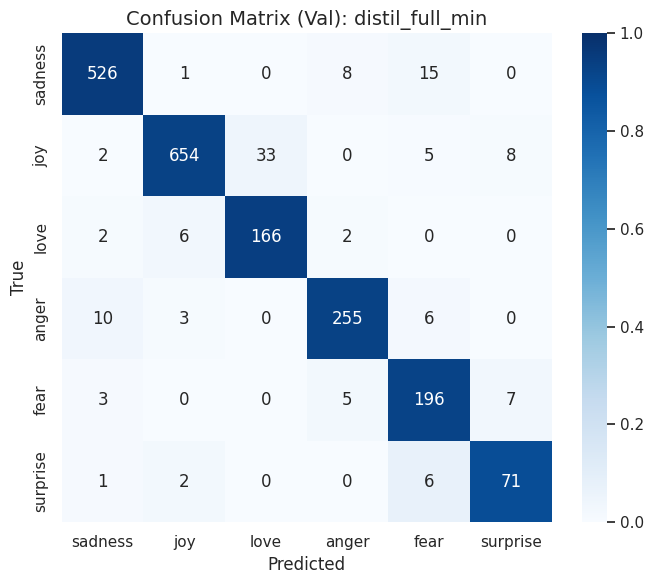

In [27]:
# ============================================================
# 22) Run distil_full_min: full fine-tune on minimal text
# ============================================================
display(Markdown("## 22. DistilBERT Full Fine-tune (distil_full_min, Val)"))

# On CPU this run would take hours instead of minutes
if device.type != "cuda":
    print("No GPU: Runtime > Change runtime type > T4 GPU, then run the notebook again.")

full_out = train_eval_transformer("distil_full_min", freeze_backbone=False)

# Per-epoch history; the reloaded best epoch must give the same val Macro-F1 as its history row
history_df = full_out["history"]
display(history_df.round(4).assign(lr=history_df["lr"].map(lambda x: f"{x:.2e}")))   # head LR at the end of each epoch
best_row = history_df.loc[history_df["val_macro_f1"].idxmax()]
print(f"Best epoch {int(best_row['epoch'])}: history val Macro-F1 {best_row['val_macro_f1']:.4f} | "
      f"reloaded model {full_out['metrics']['macro_f1']:.4f}")

display(per_class_table(y_val, full_out["val_pred"]))
plot_confusion_matrix(y_val, full_out["val_pred"], "Confusion Matrix (Val): distil_full_min",
                      save_name="a2_cm_val_distil_full_min.png")

## Repeated seeds: DistilBERT full fine-tune
One run cannot show how much the result moves by chance. `distil_full_min` (seed 42) is repeated with seeds 43 and 44 (`SEEDS` in the config cell); only the seed changes, which changes the head initialisation, dropout and the train batch order. The mean ± std of val Macro-F1 over the three seeds is the yardstick for every later comparison: a difference smaller than this spread is not evidence that one setting is better.

In [28]:
# ============================================================
# 22b) DistilBERT full fine-tune: two more seeds
# ============================================================
display(Markdown("## 22b. DistilBERT Full Fine-tune: Seeds (Val)"))

# Seed 42 is distil_full_min from the cell above; the other seeds get the seed in the run name.
# Only the seed changes: head initialisation, dropout and the train batch order.
full_seed_outs = {SEED: full_out}
for seed in SEEDS:
    if seed != SEED:
        full_seed_outs[seed] = train_eval_transformer(f"distil_full_min_s{seed}", seed=seed)

def seed_table(outs):
    # One row per seed (val metrics, best epoch), then mean, std (sample std over the seeds), min and max.
    # The spread over seeds is the yardstick for comparing runs.
    rows = []
    for seed, out in outs.items():
        hist = out["history"]
        rows.append({"seed": seed, **out["metrics"], "best_epoch": int(hist.loc[hist["val_macro_f1"].idxmax(), "epoch"])})
    per_seed = pd.DataFrame(rows).set_index("seed")
    summary = per_seed[["acc", "macro_f1", "weighted_f1"]].agg(["mean", "std", "min", "max"])
    return per_seed, summary

seed_df, distil_seed_summary = seed_table(full_seed_outs)
display(seed_df.round(4))
display(distil_seed_summary.round(4))
print(f"DistilBERT full fine-tune, {len(seed_df)} seeds: val Macro-F1 "
      f"{distil_seed_summary.loc['mean', 'macro_f1']:.4f} ± {distil_seed_summary.loc['std', 'macro_f1']:.4f} "
      f"(range {distil_seed_summary.loc['min', 'macro_f1']:.4f}-{distil_seed_summary.loc['max', 'macro_f1']:.4f})")

## 22b. DistilBERT Full Fine-tune: Seeds (Val)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[distil_full_min_s43] loaded from /content/drive/MyDrive/DL/A2/checkpoints/distil_full_min_s43 (best epoch 3)
[distil_full_min_s43] best epoch 3 | val acc 0.9378 | val macro_f1 0.9178 | train 245.9 s | 1.406 ms/text | trainable 66,958,086 of 66,958,086 params


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[distil_full_min_s44] loaded from /content/drive/MyDrive/DL/A2/checkpoints/distil_full_min_s44 (best epoch 3)
[distil_full_min_s44] best epoch 3 | val acc 0.9368 | val macro_f1 0.9140 | train 251.2 s | 1.415 ms/text | trainable 66,958,086 of 66,958,086 params


,acc,macro_f1,weighted_f1,best_epoch
seed,,,,
42,0.9373,0.9148,0.9381,3
43,0.9378,0.9178,0.9385,3
44,0.9368,0.9140,0.9375,3


,acc,macro_f1,weighted_f1
mean,0.9373,0.9155,0.9380
std,0.0005,0.0020,0.0005
min,0.9368,0.9140,0.9375
max,0.9378,0.9178,0.9385


DistilBERT full fine-tune, 3 seeds: val Macro-F1 0.9155 ± 0.0020 (range 0.9140-0.9178)


## BERT full fine-tune: `bert_full_min` (3 seeds)
Added on 2026-10-27, while time remained before M3: `bert-base-uncased` (12 layers, about 110M parameters, about 1.6× DistilBERT) trained with exactly the same recipe and the same three seeds as the DistilBERT full fine-tune (learning rates, batch 16, 3 epochs, warmup, class weights, checkpoint by val Macro-F1), to see what a larger model changes. This is the second controlled experiment: the only factor changed is the pretrained model (everything else, including the token ids and the batch order, is identical). The factor is the model as a whole (12 vs 6 layers, BERT's pretrained pooler, no distillation), so a difference shows whether BERT differs, not which part causes it. Nothing is tuned for either model. Both models have three seeds, so they are compared by mean ± std and seed by seed (the same seed gives the same train batch order). Seed 42 (`bert_full_min`) is the main BERT run in the tables and figures.

## 22c. BERT Full Fine-tune: Seeds (Val)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

[bert_full_min_s44] best epoch 3 | val acc 0.9368 | val macro_f1 0.9145 | train 499.7 s | 3.050 ms/text | trainable 109,486,854 of 109,486,854 params


,acc,macro_f1,weighted_f1,best_epoch
seed,,,,
42,0.9418,0.9200,0.9420,2
43,0.9363,0.9145,0.9370,3
44,0.9368,0.9145,0.9376,3


,acc,macro_f1,weighted_f1
mean,0.9383,0.9163,0.9389
std,0.0031,0.0032,0.0027
min,0.9363,0.9145,0.9370
max,0.9418,0.9200,0.9420


,epoch,train_loss,val_loss,val_acc,val_macro_f1,val_weighted_f1,lr
0,1,0.8013,0.2524,0.9212,0.8979,0.9217,7.41e-05
1,2,0.1896,0.2103,0.9418,0.9200,0.9420,3.70e-05
2,3,0.1156,0.1966,0.9363,0.9154,0.9371,0.00e+00


,precision,recall,f1-score,support
sadness,0.9436,0.9727,0.9579,550.0000
joy,0.9669,0.9573,0.9621,702.0000
love,0.9191,0.9034,0.9112,176.0000
anger,0.9656,0.9234,0.9440,274.0000
fear,0.9372,0.8483,0.8905,211.0000
surprise,0.7524,0.9875,0.8541,80.0000
accuracy,0.9418,0.9418,0.9418,0.9418
macro avg,0.9141,0.9321,0.9200,1993.0000
weighted avg,0.9443,0.9418,0.9420,1993.0000


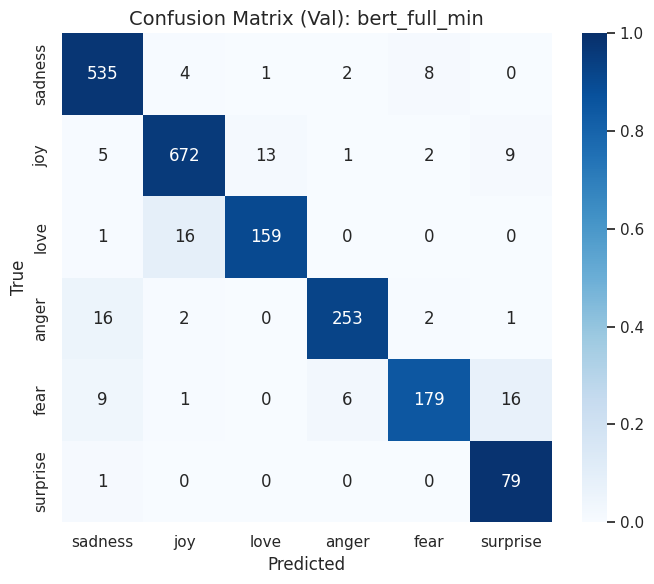

,DistilBERT,BERT,BERT - DistilBERT
seed,,,
42,0.9148,0.9200,0.0051
43,0.9178,0.9145,-0.0033
44,0.9140,0.9145,0.0005


DistilBERT val Macro-F1 0.9155 ± 0.0020 (range 0.9140-0.9178)
BERT       val Macro-F1 0.9163 ± 0.0032 (range 0.9145-0.9200)
BERT - DistilBERT: mean +0.0008 | BERT higher on 2 of 3 seeds


In [29]:
# ============================================================
# 22c) BERT full fine-tune (second controlled experiment: BERT vs DistilBERT)
# ============================================================
display(Markdown("## 22c. BERT Full Fine-tune: Seeds (Val)"))

# BERT and DistilBERT (uncased) share the WordPiece vocabulary. If they also give the same token ids
# for every text, the DataLoaders and MAX_LEN = 128 from the DistilBERT cells are reused unchanged.
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
same_ids = all(bert_tokenizer(part["text_min"].tolist())["input_ids"] == tokenizer(part["text_min"].tolist())["input_ids"]
               for part in [train_df, val_df])
print("Same vocabulary:", bert_tokenizer.get_vocab() == tokenizer.get_vocab(), "| same token ids on train and val:", same_ids)
if not same_ids:
    raise ValueError("The BERT tokenizer differs from DistilBERT's: build separate DataLoaders for BERT")

# Same recipe and the same three seeds as the DistilBERT full fine-tune; only the model changes.
# Seed 42 keeps the plain name and is the main BERT run in the tables and figures.
bert_seed_outs = {}
for seed in SEEDS:
    run_name = "bert_full_min" if seed == SEED else f"bert_full_min_s{seed}"
    bert_seed_outs[seed] = train_eval_transformer(run_name, model_name=BERT_MODEL_NAME, seed=seed)
bert_out = bert_seed_outs[SEED]

bert_seed_df, bert_seed_summary = seed_table(bert_seed_outs)
display(bert_seed_df.round(4))
display(bert_seed_summary.round(4))

# Main BERT run (seed 42): history, per class, confusion matrix
bert_hist = bert_out["history"]
display(bert_hist.round(4).assign(lr=bert_hist["lr"].map(lambda x: f"{x:.2e}")))   # head LR at the end of each epoch
display(per_class_table(y_val, bert_out["val_pred"]))
plot_confusion_matrix(y_val, bert_out["val_pred"], "Confusion Matrix (Val): bert_full_min",
                      save_name="a2_cm_val_bert_full_min.png")

# BERT vs DistilBERT seed by seed: the same seed gives both models the same train batch order
paired = pd.DataFrame({"DistilBERT": seed_df["macro_f1"], "BERT": bert_seed_df["macro_f1"]})
paired["BERT - DistilBERT"] = paired["BERT"] - paired["DistilBERT"]
display(paired.round(4))
for name, summary in [("DistilBERT", distil_seed_summary), ("BERT", bert_seed_summary)]:
    print(f"{name:10s} val Macro-F1 {summary.loc['mean', 'macro_f1']:.4f} ± {summary.loc['std', 'macro_f1']:.4f} "
          f"(range {summary.loc['min', 'macro_f1']:.4f}-{summary.loc['max', 'macro_f1']:.4f})")
diff = paired["BERT - DistilBERT"]
print(f"BERT - DistilBERT: mean {diff.mean():+.4f} | BERT higher on {(diff > 0).sum()} of {len(diff)} seeds")

# Preliminary Results

## Results on validation
All runs so far on **val only**, ranked by Macro-F1 (the selection metric), with Accuracy beside it as the handbook requires; weighted-F1 is shown for reference only. The majority-class floor is added as a reference row. A second table gives Macro-F1 per model and setup over the seeds. Then the main run of each model (seed 42: selected baseline, `distil_full_min`, `bert_full_min`) is compared per class (F1), text by text (which texts only one model gets right), and by cost. The baseline ran on CPU and the transformers on the T4 GPU, so the time ratios compare the two setups as used, not the two models on the same hardware. Test is not used here.

In [30]:
# ============================================================
# 23) Preliminary results (val)
# ============================================================
display(Markdown("## 23. Preliminary Results (Val)"))

# Every run so far, val only: test is used once, after model selection.
# Accuracy and Macro-F1 are the required metrics; Macro-F1 ranks the runs, weighted-F1 is for reference.
results_df = pd.DataFrame(results)
show_cols = ["run", "model", "setup", "seed", "acc", "macro_f1", "weighted_f1",
             "train_time_s", "infer_ms", "trainable_params", "size_mb", "hardware"]
val_results = results_df[results_df["split"] == "val"][show_cols]

# The majority-class floor from the helper cell as a reference row (no model, nothing trained)
floor_row = {"run": "majority_class", "model": f"always '{id2label[majority]}'", "setup": "-", **majority_metrics}
val_results = pd.concat([val_results, pd.DataFrame([floor_row])], ignore_index=True)
val_results = val_results.sort_values("macro_f1", ascending=False).set_index("run")
val_results["trainable_params"] = val_results["trainable_params"].astype("Int64")   # whole numbers, empty for the floor
val_results["seed"] = val_results["seed"].astype("Int64")                           # transformer runs only
display(val_results.round(4).astype(object).fillna("-"))

# Per model and setup over the seeds (DistilBERT and BERT full fine-tune: 3 seeds each, baseline: 1 run)
seed_summary = val_results.drop(index="majority_class").groupby(["model", "setup"])["macro_f1"].agg(
    ["count", "mean", "std", "min", "max"])
display(seed_summary.round(4))

# F1 per class of the main run of each model (seed 42): which emotions gain the most
compare_preds = {best_baseline: baseline_runs[best_baseline]["val_pred"],
                 "distil_full_min": full_out["val_pred"], "bert_full_min": bert_out["val_pred"]}
rows = label_names + ["macro avg"]
f1_compare = pd.DataFrame({"support": per_class_table(y_val, full_out["val_pred"]).loc[rows, "support"].astype(int)})
for run_name, pred in compare_preds.items():
    f1_compare[run_name] = per_class_table(y_val, pred).loc[rows, "f1-score"]
f1_compare["DistilBERT - baseline"] = f1_compare["distil_full_min"] - f1_compare[best_baseline]
f1_compare["BERT - DistilBERT"] = f1_compare["bert_full_min"] - f1_compare["distil_full_min"]
display(f1_compare.round(4))

# Text by text: a higher score can still hide texts that only the other model gets right
def agreement(run_a, run_b):
    ok_a = compare_preds[run_a] == y_val
    ok_b = compare_preds[run_b] == y_val
    print(f"{run_a} vs {run_b}: both right {np.sum(ok_a & ok_b)} | only {run_b} right {np.sum(~ok_a & ok_b)} | "
          f"only {run_a} right {np.sum(ok_a & ~ok_b)} | both wrong {np.sum(~ok_a & ~ok_b)}")

print(f"Val texts: {len(y_val)}")
agreement(best_baseline, "distil_full_min")
agreement("distil_full_min", "bert_full_min")

# Cost of the gains. The baseline ran on CPU and the transformers on the T4 GPU, so baseline time ratios
# compare the two setups as used, not the two models on the same hardware.
cost_cols = ["train_time_s", "infer_ms", "trainable_params", "size_mb"]
for run_a, run_b in [(best_baseline, "distil_full_min"), ("distil_full_min", "bert_full_min")]:
    ratio = val_results.loc[run_b, cost_cols].astype(float) / val_results.loc[run_a, cost_cols].astype(float)
    print(f"{run_b} / {run_a}:", " | ".join(f"{col} x{value:,.1f}" for col, value in ratio.items()))

## 23. Preliminary Results (Val)

,model,setup,seed,acc,macro_f1,weighted_f1,train_time_s,infer_ms,trainable_params,size_mb,hardware
run,,,,,,,,,,,
bert_full_min,BERT,full fine-tune,42,0.9418,0.9200,0.9420,502.63,3.0624,109486854,418.36,GPU: Tesla T4
distil_full_min_s43,DistilBERT,full fine-tune,43,0.9378,0.9178,0.9385,245.92,1.4063,66958086,256.12,GPU: Tesla T4
distil_full_min,DistilBERT,full fine-tune,42,0.9373,0.9148,0.9381,252.65,1.3905,66958086,256.12,GPU: Tesla T4
bert_full_min_s44,BERT,full fine-tune,44,0.9368,0.9145,0.9376,499.67,3.05,109486854,418.36,GPU: Tesla T4
bert_full_min_s43,BERT,full fine-tune,43,0.9363,0.9145,0.9370,499.42,3.0454,109486854,418.36,GPU: Tesla T4
distil_full_min_s44,DistilBERT,full fine-tune,44,0.9368,0.9140,0.9375,251.24,1.4153,66958086,256.12,GPU: Tesla T4
tfidf_lr_min_cw,TF-IDF + LR,class weights on,-,0.8751,0.8489,0.8760,5.79,0.0244,196662,2.23,CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
tfidf_lr_min_nocw,TF-IDF + LR,class weights off,-,0.8289,0.7527,0.8187,7.17,0.0276,196662,2.23,CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
majority_class,always 'joy',-,-,0.3522,0.0868,0.1835,-,-,-,-,-


count    mean     std     min     max
model       setup                                                   
BERT        full fine-tune         3  0.9163  0.0032  0.9145  0.9200
DistilBERT  full fine-tune         3  0.9155  0.0020  0.9140  0.9178
TF-IDF + LR class weights off      1  0.7527     NaN  0.7527  0.7527
            class weights on       1  0.8489     NaN  0.8489  0.8489

,support,tfidf_lr_min_cw,distil_full_min,bert_full_min,DistilBERT - baseline,BERT - DistilBERT
sadness,550,0.8959,0.9616,0.9579,0.0657,-0.0037
joy,702,0.9004,0.9561,0.9621,0.0557,0.0060
love,176,0.8354,0.8853,0.9112,0.0499,0.0259
anger,274,0.8800,0.9375,0.9440,0.0575,0.0065
fear,211,0.8124,0.8929,0.8905,0.0805,-0.0024
surprise,80,0.7692,0.8554,0.8541,0.0862,-0.0013
macro avg,1993,0.8489,0.9148,0.9200,0.0659,0.0052


Val texts: 1993
tfidf_lr_min_cw vs distil_full_min: both right 1706 | only distil_full_min right 162 | only tfidf_lr_min_cw right 38 | both wrong 87
distil_full_min vs bert_full_min: both right 1821 | only bert_full_min right 56 | only distil_full_min right 47 | both wrong 69
distil_full_min / tfidf_lr_min_cw: train_time_s x43.6 | infer_ms x57.0 | trainable_params x340.5 | size_mb x114.9
bert_full_min / distil_full_min: train_time_s x2.0 | infer_ms x2.2 | trainable_params x1.6 | size_mb x1.6


## Training curves
Drawn from `history_<run>.csv`, so the figure can be rebuilt without wandb (the wandb run is the experiment log; its id is in `wandb_ids.json`). Left: train and val loss per epoch (the gap shows over- or underfitting). Middle: val Macro-F1 per epoch with the saved epoch circled and the selected baseline as a reference line. Right: the learning rate per optimizer step from the warmup + linear-decay formula, for the head and the backbone; the head LR logged at the end of each epoch is drawn on top as a check. The main run (seed 42) of DistilBERT (solid) and BERT (dash-dot) are drawn together; add `"distil_freeze_min"` to `CURVE_RUNS` after the controlled experiment.

## 24. Training Curves (DistilBERT, BERT)

distil_full_min: best epoch 3, val Macro-F1 0.9148 | val loss 0.2384 -> 0.1974 | train loss 0.6689 -> 0.1174
bert_full_min: best epoch 2, val Macro-F1 0.9200 | val loss 0.2524 -> 0.1966 | train loss 0.8013 -> 0.1156


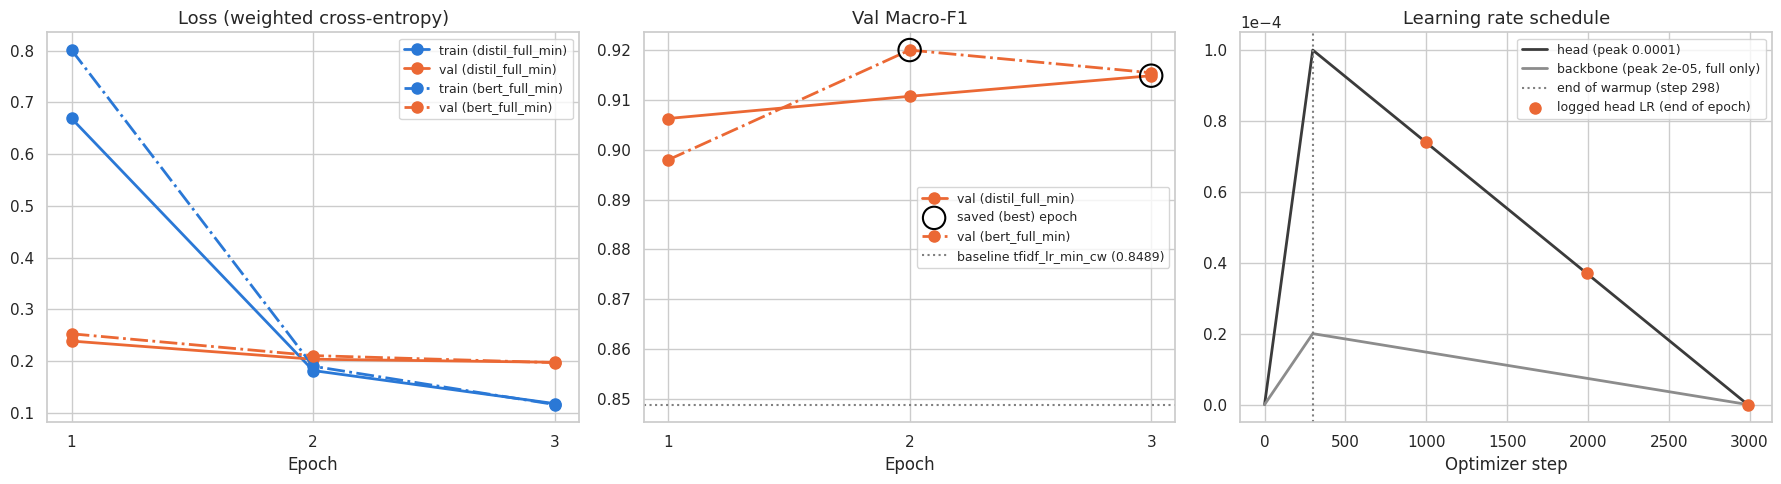

In [31]:
# ============================================================
# 24) Training curves
# ============================================================
display(Markdown("## 24. Training Curves (DistilBERT, BERT)"))

# Main run (seed 42) of each model; add "distil_freeze_min" after the controlled experiment
CURVE_RUNS = ["distil_full_min", "bert_full_min"]
RUN_STYLES = {"distil_full_min": "-", "bert_full_min": "-.", "distil_freeze_min": "--"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, run_name in enumerate(CURVE_RUNS):
    hist = pd.read_csv(os.path.join(RESULTS_DIR, f"history_{run_name}.csv"))
    style = RUN_STYLES[run_name]

    # Loss: train and val together, so a growing gap (overfitting) is visible
    axes[0].plot(hist["epoch"], hist["train_loss"], style, marker="o", ms=8, lw=2,
                 color=SPLIT_COLORS["train"], label=f"train ({run_name})")
    axes[0].plot(hist["epoch"], hist["val_loss"], style, marker="o", ms=8, lw=2,
                 color=SPLIT_COLORS["val"], label=f"val ({run_name})")

    # Val Macro-F1, the selection metric; the ring marks the epoch that was saved
    axes[1].plot(hist["epoch"], hist["val_macro_f1"], style, marker="o", ms=8, lw=2,
                 color=SPLIT_COLORS["val"], label=f"val ({run_name})")
    best = hist.loc[hist["val_macro_f1"].idxmax()]
    axes[1].scatter(best["epoch"], best["val_macro_f1"], s=260, facecolors="none", edgecolors="black",
                    lw=1.5, zorder=3, label="saved (best) epoch" if i == 0 else None)
    print(f"{run_name}: best epoch {int(best['epoch'])}, val Macro-F1 {best['val_macro_f1']:.4f} | "
          f"val loss {hist['val_loss'].iloc[0]:.4f} -> {hist['val_loss'].iloc[-1]:.4f} | "
          f"train loss {hist['train_loss'].iloc[0]:.4f} -> {hist['train_loss'].iloc[-1]:.4f}")

base_f1 = compare_df.loc[best_baseline, "Macro-F1"]
axes[1].axhline(base_f1, color="gray", ls=":", lw=1.5, label=f"baseline {best_baseline} ({base_f1:.4f})")

# LR per step, from the same formula as get_linear_schedule_with_warmup:
# rises from 0 to the peak during warmup, then falls linearly to 0
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)
steps = np.arange(total_steps + 1)
factor = np.where(steps < warmup_steps, steps / warmup_steps, (total_steps - steps) / (total_steps - warmup_steps))
axes[2].plot(steps, LR_HEAD * factor, color="#3b3b3b", lw=2, label=f"head (peak {LR_HEAD:g})")
axes[2].plot(steps, LR_BACKBONE * factor, color="#8c8c8c", lw=2, label=f"backbone (peak {LR_BACKBONE:g}, full only)")
axes[2].axvline(warmup_steps, color="gray", ls=":", lw=1.5, label=f"end of warmup (step {warmup_steps})")
# The head LR logged at the end of each epoch must sit on the head line
hist = pd.read_csv(os.path.join(RESULTS_DIR, f"history_{CURVE_RUNS[0]}.csv"))
axes[2].scatter(hist["epoch"] * len(train_loader), hist["lr"], s=64, color=SPLIT_COLORS["val"], zorder=3,
                label="logged head LR (end of epoch)")

titles = ["Loss (weighted cross-entropy)", "Val Macro-F1", "Learning rate schedule"]
xlabels = ["Epoch", "Epoch", "Optimizer step"]
for ax, title, xlabel in zip(axes, titles, xlabels):
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=9)
for ax in axes[:2]:
    ax.set_xticks(range(1, EPOCHS + 1))
axes[2].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_curves.png"), dpi=150)
plt.show()

# Export

## Partial export (M2)
Writes the files the report page reads into `RESULTS_DIR` on Drive: `results.csv` (one row per run and split, val only for now, plus a `seed` column), `split_stats.csv` (class counts and shares per split after filtering), `hardware.json` (hardware and library versions) and `per_class_val_<run>.csv` for the selected baseline, `distil_full_min` and `bert_full_min`. `history_<run>.csv`, `wandb_ids.json` and the figures were already written by earlier cells. The whole folder is zipped to `results_export.zip` next to it: download that one file and unzip it into the project's `results/` folder. Test rows and test per-class tables are added by the full export after model selection.

In [32]:
# ============================================================
# 25) Partial export (M2)
# ============================================================
display(Markdown("## 25. Partial Export (M2)"))

# One row per run and split, in the column order the site expects (val rows only so far);
# "seed" is extra and empty for the baseline, whose LogReg solver is deterministic
RESULT_COLS = ["run", "model", "text", "setup", "split", "acc", "macro_f1", "weighted_f1", "train_time_s",
               "infer_ms", "total_params", "trainable_params", "size_mb", "hardware", "seed"]
results_df = pd.DataFrame(results)[RESULT_COLS]
results_df["seed"] = results_df["seed"].astype("Int64")   # 42, not 42.0
results_df.to_csv(os.path.join(RESULTS_DIR, "results.csv"), index=False)
display(results_df[["run", "split", "acc", "macro_f1"]])

# Class counts and shares per split after filtering
split_stats.to_csv(os.path.join(RESULTS_DIR, "split_stats.csv"))

# Hardware and library versions for the reproducibility section
with open(os.path.join(RESULTS_DIR, "hardware.json"), "w") as f:
    json.dump(hardware_info, f, indent=2)

# Per-class val results of the main run of each model; the test tables come after model selection
val_preds = {best_baseline: baseline_runs[best_baseline]["val_pred"], "distil_full_min": full_out["val_pred"],
             "bert_full_min": bert_out["val_pred"]}
for run_name, pred in val_preds.items():
    per_class_table(y_val, pred).to_csv(os.path.join(RESULTS_DIR, f"per_class_val_{run_name}.csv"))

# history_<run>.csv, wandb_ids.json and the figures were already written by the earlier cells.
# Everything goes into one zip next to the results folder: download it from Drive and unzip into results/
zip_path = shutil.make_archive(os.path.join(BASE_DIR, "results_export"), "zip", RESULTS_DIR)

print("\nFiles in", RESULTS_DIR)
for root, _, files in os.walk(RESULTS_DIR):
    for name in sorted(files):
        path = os.path.join(root, name)
        print(f"  {os.path.relpath(path, RESULTS_DIR):45s} {os.path.getsize(path) / 1024:8.1f} KB")
print(f"\nZip: {zip_path} ({os.path.getsize(zip_path) / 1024**2:.2f} MB)")

## 25. Partial Export (M2)

,run,split,acc,macro_f1
0,tfidf_lr_min_nocw,val,0.828901,0.752734
1,tfidf_lr_min_cw,val,0.875063,0.848883
2,distil_full_min,val,0.937280,0.914824
3,distil_full_min_s43,val,0.937782,0.917798
4,distil_full_min_s44,val,0.936779,0.914015
5,bert_full_min,val,0.941796,0.919965
6,bert_full_min_s43,val,0.936277,0.914476
7,bert_full_min_s44,val,0.936779,0.914490



Files in /content/drive/MyDrive/DL/A2/results
  hardware.json                                      0.3 KB
  history_bert_full_min.csv                          0.4 KB
  history_bert_full_min_s43.csv                      0.4 KB
  history_bert_full_min_s44.csv                      0.4 KB
  history_distil_full_min.csv                        0.4 KB
  history_distil_full_min_s43.csv                    0.4 KB
  history_distil_full_min_s44.csv                    0.4 KB
  per_class_val_bert_full_min.csv                    0.3 KB
  per_class_val_distil_full_min.csv                  0.3 KB
  per_class_val_tfidf_lr_min_cw.csv                  0.3 KB
  results.csv                                        1.5 KB
  split_stats.csv                                    0.3 KB
  wandb_ids.json                                     0.3 KB
  figures/a2_class_dist.png                         67.6 KB
  figures/a2_cm_val_bert_full_min.png               62.8 KB
  figures/a2_cm_val_distil_full_min.png             6